# Question 2

In [3]:
import gzip
import pickle
import copy
import yaml
import numpy as np
import matplotlib.pyplot as plt

In [4]:
with open("../config/config.yaml", "r") as f:
    config = yaml.safe_load(f)

selected_config = copy.deepcopy(config)

In [191]:
def load_mnist(path):
    with gzip.open(path, "rb") as f:
        data = pickle.load(f, encoding="latin1")
    (x_train, y_train), (x_val, y_val), (x_test, y_test) = data
    return x_train, y_train, x_val, y_val, x_test, y_test


def one_hot(y, num_classes):
    y_oh = np.zeros((y.shape[0], num_classes), dtype=np.float64)
    y_oh[np.arange(y.shape[0]), y] = 1.0
    return y_oh


def standardize_data(x_train, x_val, x_test, eps=1e-8):
    mean = x_train.mean(axis=0, keepdims=True)
    std = x_train.std(axis=0, keepdims=True)
    std = np.where(std < eps, 1.0, std)

    x_train_std = (x_train - mean) / std
    x_val_std = (x_val - mean) / std
    x_test_std = (x_test - mean) / std

    return x_train_std, x_val_std, x_test_std


def prepare_data(x_train, x_val, x_test, normalization="none"):
    if normalization == "none":
        return x_train.copy(), x_val.copy(), x_test.copy()
    elif normalization == "standardize":
        return standardize_data(x_train, x_val, x_test)
    else:
        raise ValueError(f"Unknown normalization mode: {normalization}")

In [192]:
mnist_path = config["data"]["mnist_path"]

x_train, y_train, x_val, y_val, x_test, y_test = load_mnist(mnist_path)

print("Train:", x_train.shape, y_train.shape)
print("Valid:", x_val.shape, y_val.shape)
print("Test :", x_test.shape, y_test.shape)

assert x_train.shape[1] == config["model"]["input_dim"], "input_dim does not match dataset shape"

Train: (50000, 784) (50000,)
Valid: (10000, 784) (10000,)
Test : (10000, 784) (10000,)


## 2.1

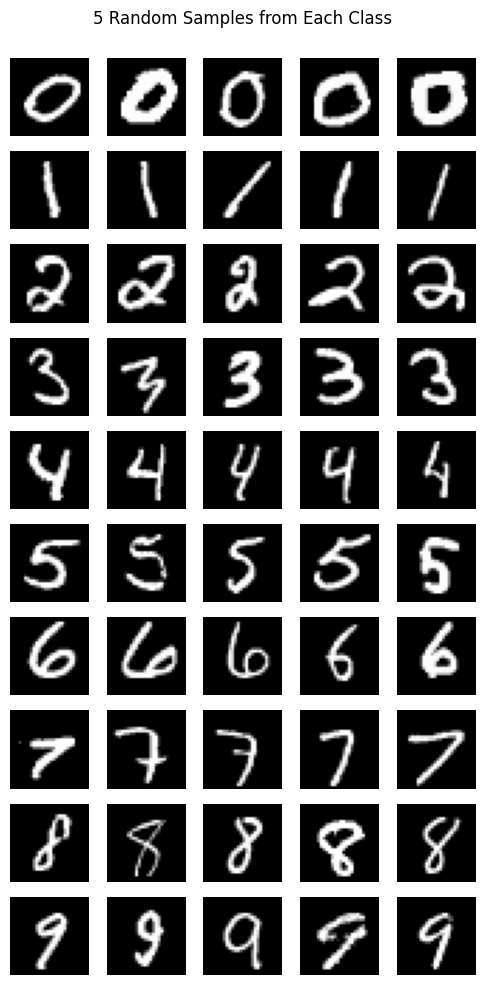

In [36]:
classes = np.unique(y_train)
fig, axes = plt.subplots(10, 5, figsize=(5, 10))

for cls in classes:
    cls_indices = np.where(y_train == cls)[0]
    chosen = np.random.choice(cls_indices, 5, replace=False)
    
    for j, idx in enumerate(chosen):
        img = x_train[idx].reshape(28, 28)
        axes[cls, j].imshow(img, cmap='gray')
        axes[cls, j].axis('off')

plt.suptitle("5 Random Samples from Each Class")
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

## Q2.2

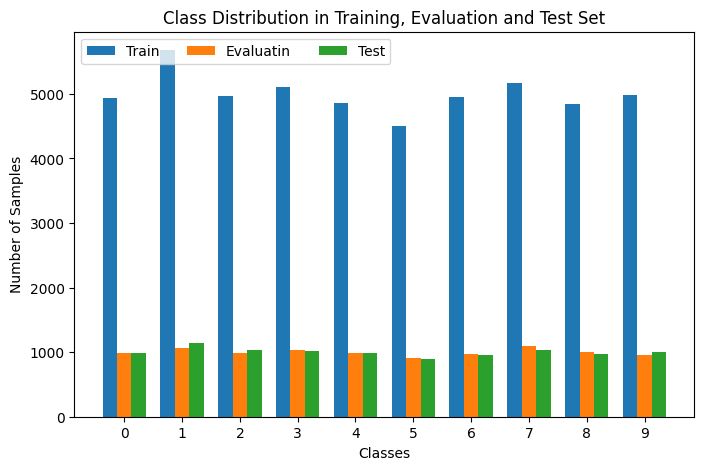

In [37]:
train_counts = np.bincount(y_train)
eval_counts = np.bincount(y_val)
test_counts = np.bincount(y_test)

width = 0.25

plt.figure(figsize=(8, 5))
plt.bar(classes - width, train_counts, width=width, label='Train')
plt.bar(classes,         eval_counts, width=width, label='Evaluatin')
plt.bar(classes + width, test_counts,  width=width, label='Test')
plt.xticks(range(10))
plt.xlabel("Classes")
plt.ylabel("Number of Samples")
plt.title("Class Distribution in Training, Evaluation and Test Set")
plt.legend(loc='upper left', ncol=3)
plt.show()

## Q2.3

In [38]:
print("Feature vector length:", x_train.shape[1])

side = int(np.sqrt(x_train.shape[1]))
print("Image size:", side, "x", side)

Feature vector length: 784
Image size: 28 x 28


## Q2.4

In [11]:
print("Shape before vectorization:", x_train.shape)

print("Each image is already a vector of length:", x_train.shape[1])

sample_img = x_train[53].reshape(28, 28)
sample_vec = sample_img.reshape(-1)

print("Image shape:", sample_img.shape)
print("Vector shape:", sample_vec.shape)

Shape before vectorization: (50000, 784)
Each image is already a vector of length: 784
Image shape: (28, 28)
Vector shape: (784,)


## Q2.6

In [40]:
print("Training set :", x_train.shape, y_train.shape)
print("Validation set:", x_val.shape, y_val.shape)
print("Test set     :", x_test.shape, y_test.shape)

Training set : (50000, 784) (50000,)
Validation set: (10000, 784) (10000,)
Test set     : (10000, 784) (10000,)


## Q2.7

In [193]:
def relu(x):
    return np.maximum(0, x)


def relu_grad(x):
    return (x > 0).astype(np.float64)


def softmax(x):
    x_shifted = x - np.max(x, axis=1, keepdims=True)
    exp_x = np.exp(x_shifted)
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)


def cross_entropy_loss(y_true_onehot, y_pred_probs, eps=1e-12):
    y_pred_probs = np.clip(y_pred_probs, eps, 1.0)
    return -np.sum(y_true_onehot * np.log(y_pred_probs)) / y_true_onehot.shape[0]


def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)


def confusion_matrix_np(y_true, y_pred, num_classes):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

In [194]:
class MLP:
    def __init__(
        self,
        input_dim,
        hidden_dims,
        output_dim,
        init_mean=0.0,
        init_std=1.0,
        bias_init=0.0,
        optimizer="sgd",
        learning_rate=1e-3,
        momentum_beta=0.9,
        l2_lambda=0.0,
        seed=42
    ):
        self.layer_dims = [input_dim] + hidden_dims + [output_dim]
        self.num_layers = len(self.layer_dims) - 1

        self.optimizer = optimizer.lower()
        self.lr = learning_rate
        self.beta = momentum_beta
        self.l2_lambda = l2_lambda

        self.rng = np.random.default_rng(seed)

        self.params = {}
        self.velocity = {}

        for l in range(1, self.num_layers + 1):
            in_dim = self.layer_dims[l - 1]
            out_dim = self.layer_dims[l]

            self.params[f"W{l}"] = self.rng.normal(
                loc=init_mean,
                scale=init_std,
                size=(in_dim, out_dim)
            )
            self.params[f"b{l}"] = np.full((1, out_dim), bias_init, dtype=np.float64)

            self.velocity[f"W{l}"] = np.zeros((in_dim, out_dim), dtype=np.float64)
            self.velocity[f"b{l}"] = np.zeros((1, out_dim), dtype=np.float64)

    def forward(self, x):
        cache = {"A0": x}
        A = x

        for l in range(1, self.num_layers):
            Z = A @ self.params[f"W{l}"] + self.params[f"b{l}"]
            A = relu(Z)
            cache[f"Z{l}"] = Z
            cache[f"A{l}"] = A

        ZL = A @ self.params[f"W{self.num_layers}"] + self.params[f"b{self.num_layers}"]
        AL = softmax(ZL)

        cache[f"Z{self.num_layers}"] = ZL
        cache[f"A{self.num_layers}"] = AL

        return AL, cache

    def l2_penalty(self, m):
        penalty = 0.0
        for l in range(1, self.num_layers + 1):
            penalty += np.sum(self.params[f"W{l}"] ** 2)
        return (self.l2_lambda / (2 * m)) * penalty

    def backward(self, y_true_onehot, cache):
        grads = {}
        m = y_true_onehot.shape[0]

        AL = cache[f"A{self.num_layers}"]
        A_prev = cache[f"A{self.num_layers - 1}"] if self.num_layers > 1 else cache["A0"]

        dZ = (AL - y_true_onehot) / m
        grads[f"W{self.num_layers}"] = A_prev.T @ dZ + (self.l2_lambda / m) * self.params[f"W{self.num_layers}"]
        grads[f"b{self.num_layers}"] = np.sum(dZ, axis=0, keepdims=True)

        dA_prev = dZ @ self.params[f"W{self.num_layers}"].T

        for l in range(self.num_layers - 1, 0, -1):
            Z = cache[f"Z{l}"]
            A_prev = cache[f"A{l - 1}"] if l - 1 > 0 else cache["A0"]

            dZ = dA_prev * relu_grad(Z)
            grads[f"W{l}"] = A_prev.T @ dZ + (self.l2_lambda / m) * self.params[f"W{l}"]
            grads[f"b{l}"] = np.sum(dZ, axis=0, keepdims=True)

            if l > 1:
                dA_prev = dZ @ self.params[f"W{l}"].T

        return grads

    def update_params(self, grads):
        for l in range(1, self.num_layers + 1):
            if self.optimizer == "sgd":
                self.params[f"W{l}"] -= self.lr * grads[f"W{l}"]
                self.params[f"b{l}"] -= self.lr * grads[f"b{l}"]

            elif self.optimizer == "momentum":
                self.velocity[f"W{l}"] = self.beta * self.velocity[f"W{l}"] - self.lr * grads[f"W{l}"]
                self.velocity[f"b{l}"] = self.beta * self.velocity[f"b{l}"] - self.lr * grads[f"b{l}"]

                self.params[f"W{l}"] += self.velocity[f"W{l}"]
                self.params[f"b{l}"] += self.velocity[f"b{l}"]

            else:
                raise ValueError(f"Unknown optimizer: {self.optimizer}")

    def predict_proba(self, x):
        probs, _ = self.forward(x)
        return probs

    def predict(self, x):
        probs = self.predict_proba(x)
        return np.argmax(probs, axis=1)

    def get_state(self):
        return {
            "params": {k: v.copy() for k, v in self.params.items()},
            "velocity": {k: v.copy() for k, v in self.velocity.items()}
        }

    def set_state(self, state):
        self.params = {k: v.copy() for k, v in state["params"].items()}
        self.velocity = {k: v.copy() for k, v in state["velocity"].items()}

In [195]:
def iterate_minibatches(X, y, batch_size, rng):
    indices = rng.permutation(X.shape[0])
    for start in range(0, X.shape[0], batch_size):
        batch_idx = indices[start:start + batch_size]
        yield X[batch_idx], y[batch_idx]


def evaluate_model(model, X, y, return_loss_parts=False):
    num_classes = model.layer_dims[-1]
    y_onehot = one_hot(y, num_classes)

    probs, _ = model.forward(X)
    ce_loss = cross_entropy_loss(y_onehot, probs)
    reg_loss = model.l2_penalty(X.shape[0])
    loss = ce_loss + reg_loss
    preds = np.argmax(probs, axis=1)
    acc = accuracy_score(y, preds)

    if return_loss_parts:
        return loss, ce_loss, reg_loss, acc, preds

    return loss, acc, preds


def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=50,
    batch_size=32,
    seed=42,
    early_stopping=False,
    patience=5,
    min_delta=0.0,
    restore_best_weights=True
):
    rng = np.random.default_rng(seed)
    num_classes = model.layer_dims[-1]

    history = {
        "train_loss": [],
        "train_ce_loss": [],
        "train_reg_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_ce_loss": [],
        "val_reg_loss": [],
        "val_acc": [],
        "stopped_epoch": None,
        "best_epoch": None,
        "best_val_loss": None
    }

    best_val_loss = np.inf
    best_epoch = -1
    best_state = None
    patience_counter = 0

    for epoch in range(epochs):
        for xb, yb in iterate_minibatches(X_train, y_train, batch_size, rng):
            yb_onehot = one_hot(yb, num_classes)

            probs, cache = model.forward(xb)
            grads = model.backward(yb_onehot, cache)
            model.update_params(grads)

        train_loss, train_ce_loss, train_reg_loss, train_acc, _ = evaluate_model(
            model, X_train, y_train, return_loss_parts=True
        )
        val_loss, val_ce_loss, val_reg_loss, val_acc, _ = evaluate_model(
            model, X_val, y_val, return_loss_parts=True
        )

        history["train_loss"].append(train_loss)
        history["train_ce_loss"].append(train_ce_loss)
        history["train_reg_loss"].append(train_reg_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_ce_loss"].append(val_ce_loss)
        history["val_reg_loss"].append(val_reg_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} (CE: {train_ce_loss:.4f}, L2: {train_reg_loss:.4f}) | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} (CE: {val_ce_loss:.4f}, L2: {val_reg_loss:.4f}) | "
            f"Val Acc: {val_acc:.4f}"
        )

        if early_stopping:
            if val_loss < best_val_loss - min_delta:
                best_val_loss = val_loss
                best_epoch = epoch + 1
                best_state = model.get_state()
                patience_counter = 0
            else:
                patience_counter += 1

            if patience_counter >= patience:
                print(
                    f"Early stopping triggered at epoch {epoch + 1}. "
                    f"Best epoch was {best_epoch} with val_loss = {best_val_loss:.4f}"
                )
                history["stopped_epoch"] = epoch + 1
                break

    if early_stopping and restore_best_weights and best_state is not None:
        model.set_state(best_state)
        print(f"Restored best model weights from epoch {best_epoch}.")

    history["best_epoch"] = best_epoch if early_stopping else len(history["val_loss"])
    history["best_val_loss"] = best_val_loss if early_stopping else min(history["val_loss"])

    return history

In [239]:
def plot_history(history, title="Training History"):
    epochs = np.arange(1, len(history["train_loss"]) + 1)

    has_reg_history =  history["train_reg_loss"][0]
    if has_reg_history > 0:
        ncols = 3
    else:
        ncols = 2

    plt.figure(figsize=(6 * ncols, 4))

    plt.subplot(1, ncols, 1)
    plt.plot(epochs, history["train_loss"], label="Train Loss")
    plt.plot(epochs, history["val_loss"], label="Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title} - Total Loss")
    plt.legend()
    plt.grid(True)

    if has_reg_history > 0 :
        plt.subplot(1, ncols, 2)
        plt.plot(epochs, history["train_reg_loss"], label="Train L2")
        plt.plot(epochs, history["val_reg_loss"], label="Val L2")
        plt.xlabel("Epoch")
        plt.ylabel("L2 Penalty")
        plt.title(f"{title} - L2 Penalty")
        plt.legend()
        plt.grid(True)

        acc_plot_idx = 3
    else:
        acc_plot_idx = 2

    plt.subplot(1, ncols, acc_plot_idx)
    plt.plot(epochs, history["train_acc"], label="Train Acc")
    plt.plot(epochs, history["val_acc"], label="Val Acc")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title} - Accuracy")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(cm, title="Confusion Matrix"):
    plt.figure(figsize=(7, 6))
    plt.imshow(cm, cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.colorbar()

    num_classes = cm.shape[0]

    plt.xticks(ticks=np.arange(num_classes), labels=np.arange(num_classes))
    plt.yticks(ticks=np.arange(num_classes), labels=np.arange(num_classes))
    
    for i in range(num_classes):
        for j in range(num_classes):
            plt.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8)

    plt.tight_layout()
    plt.show()


In [219]:
def build_model_from_config(config):
    return MLP(
        input_dim=config["model"]["input_dim"],
        hidden_dims=config["model"]["hidden_dims"],
        output_dim=config["model"]["output_dim"],
        init_mean=config["init"]["mean"],
        init_std=config["init"]["std"],
        bias_init=config["init"]["bias"],
        optimizer=config["train"]["optimizer"],
        learning_rate=config["train"]["learning_rate"],
        momentum_beta=config["train"]["momentum_beta"],
        l2_lambda=config["train"].get("l2_lambda", 0.0),
        seed=config["seed"]
    )


def run_experiment(
    config,
    x_train, y_train,
    x_val, y_val,
    x_test, y_test,
    exp_name="experiment",
    early_stopping=False,
    patience=5,
    min_delta=0.0
):
    x_train_p, x_val_p, x_test_p = prepare_data(
        x_train,
        x_val,
        x_test,
        normalization=config["preprocessing"]["normalization"]
    )

    model = build_model_from_config(config)

    history = train_model(
        model,
        x_train_p, y_train,
        x_val_p, y_val,
        epochs=config["train"]["epochs"],
        batch_size=config["train"]["batch_size"],
        seed=config["seed"],
        early_stopping=early_stopping,
        patience=patience,
        min_delta=min_delta,
        restore_best_weights=True
    )

    train_loss, train_ce_loss, train_reg_loss, train_acc, train_preds = evaluate_model(
        model, x_train_p, y_train, return_loss_parts=True
    )
    val_loss, val_ce_loss, val_reg_loss, val_acc, val_preds = evaluate_model(
        model, x_val_p, y_val, return_loss_parts=True
    )
    test_loss, test_ce_loss, test_reg_loss, test_acc, test_preds = evaluate_model(
        model, x_test_p, y_test, return_loss_parts=True
    )

    print(
        f"\n[{exp_name}] Final Validation -> "
        f"Loss: {val_loss:.4f} (CE: {val_ce_loss:.4f}, L2: {val_reg_loss:.4f}), Acc: {val_acc:.4f}"
    )
    print(
        f"[{exp_name}] Final Test       -> "
        f"Loss: {test_loss:.4f} (CE: {test_ce_loss:.4f}, L2: {test_reg_loss:.4f}), Acc: {test_acc:.4f}"
    )

    if early_stopping:
        print(
            f"[{exp_name}] Best Epoch: {history['best_epoch']} | "
            f"Stopped Epoch: {history['stopped_epoch']}"
        )

    num_classes = config["model"]["output_dim"]
    cm = confusion_matrix_np(y_val, val_preds, num_classes=num_classes)
    test_cm = confusion_matrix_np(y_test, test_preds, num_classes=num_classes)

    plot_history(history, title=exp_name)
    plot_confusion_matrix(cm, title=f"{exp_name} - Validation Confusion Matrix")

    return {
        "model": model,
        "history": history,

        "train_loss": train_loss,
        "train_ce_loss": train_ce_loss,
        "train_reg_loss": train_reg_loss,
        "train_acc": train_acc,

        "val_loss": val_loss,
        "val_ce_loss": val_ce_loss,
        "val_reg_loss": val_reg_loss,
        "val_acc": val_acc,
        "val_cm": cm,

        "test_loss": test_loss,
        "test_ce_loss": test_ce_loss,
        "test_reg_loss": test_reg_loss,
        "test_acc": test_acc,
        "test_cm": test_cm,
        
        "best_epoch": history["best_epoch"],
        "stopped_epoch": history["stopped_epoch"]
    }

## Q2.7

Epoch 01/50 | Train Loss: 5.1742 (CE: 5.1742, L2: 0.0000) | Train Acc: 0.2315 | Val Loss: 5.0820 (CE: 5.0820, L2: 0.0000) | Val Acc: 0.2407
Epoch 02/50 | Train Loss: 3.2217 (CE: 3.2217, L2: 0.0000) | Train Acc: 0.2623 | Val Loss: 3.1257 (CE: 3.1257, L2: 0.0000) | Val Acc: 0.2799
Epoch 03/50 | Train Loss: 2.5976 (CE: 2.5976, L2: 0.0000) | Train Acc: 0.2968 | Val Loss: 2.5128 (CE: 2.5128, L2: 0.0000) | Val Acc: 0.3064
Epoch 04/50 | Train Loss: 2.3161 (CE: 2.3161, L2: 0.0000) | Train Acc: 0.3138 | Val Loss: 2.2390 (CE: 2.2390, L2: 0.0000) | Val Acc: 0.3222
Epoch 05/50 | Train Loss: 2.1599 (CE: 2.1599, L2: 0.0000) | Train Acc: 0.3286 | Val Loss: 2.0906 (CE: 2.0906, L2: 0.0000) | Val Acc: 0.3357
Epoch 06/50 | Train Loss: 2.0615 (CE: 2.0615, L2: 0.0000) | Train Acc: 0.3362 | Val Loss: 1.9966 (CE: 1.9966, L2: 0.0000) | Val Acc: 0.3440
Epoch 07/50 | Train Loss: 1.9916 (CE: 1.9916, L2: 0.0000) | Train Acc: 0.3452 | Val Loss: 1.9291 (CE: 1.9291, L2: 0.0000) | Val Acc: 0.3533
Epoch 08/50 | Train 

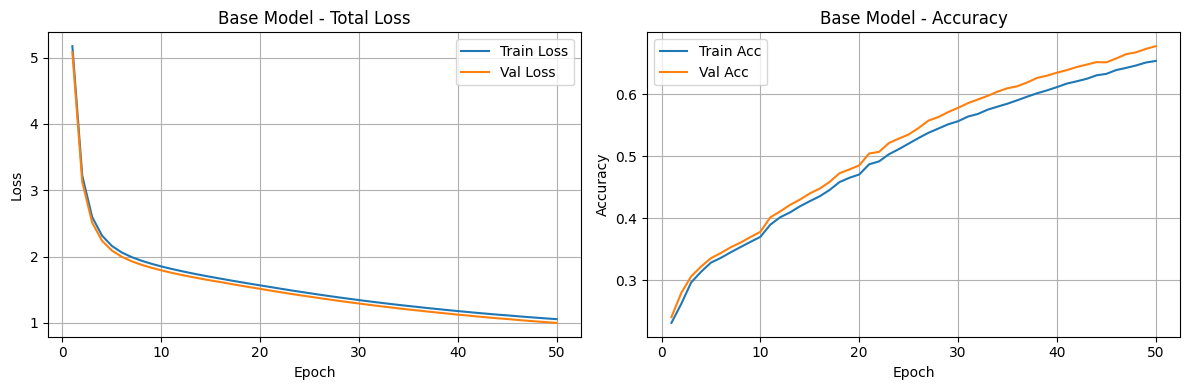

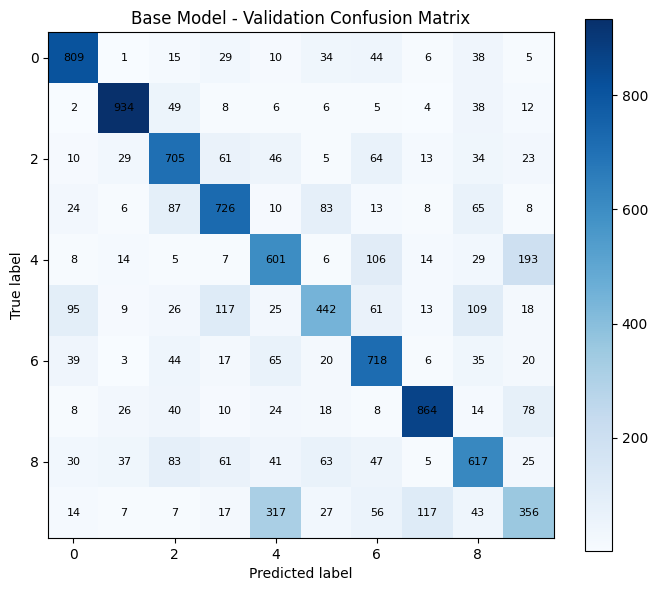

In [205]:
base_results = run_experiment(
    config,
    x_train, y_train,
    x_val, y_val,
    x_test, y_test,
    exp_name="Base Model",
    early_stopping=False
)

## Q2.8

Epoch 01/50 | Train Loss: 18.1039 (CE: 18.1039, L2: 0.0000) | Train Acc: 0.1261 | Val Loss: 18.1749 (CE: 18.1749, L2: 0.0000) | Val Acc: 0.1268
Epoch 02/50 | Train Loss: 17.7834 (CE: 17.7834, L2: 0.0000) | Train Acc: 0.1269 | Val Loss: 17.8634 (CE: 17.8634, L2: 0.0000) | Val Acc: 0.1275
Epoch 03/50 | Train Loss: 17.4741 (CE: 17.4741, L2: 0.0000) | Train Acc: 0.1279 | Val Loss: 17.5643 (CE: 17.5643, L2: 0.0000) | Val Acc: 0.1275
Epoch 04/50 | Train Loss: 17.1741 (CE: 17.1741, L2: 0.0000) | Train Acc: 0.1288 | Val Loss: 17.2745 (CE: 17.2745, L2: 0.0000) | Val Acc: 0.1281
Epoch 05/50 | Train Loss: 16.8825 (CE: 16.8825, L2: 0.0000) | Train Acc: 0.1298 | Val Loss: 16.9911 (CE: 16.9911, L2: 0.0000) | Val Acc: 0.1296
Epoch 06/50 | Train Loss: 16.5995 (CE: 16.5995, L2: 0.0000) | Train Acc: 0.1309 | Val Loss: 16.7114 (CE: 16.7114, L2: 0.0000) | Val Acc: 0.1301
Epoch 07/50 | Train Loss: 16.3227 (CE: 16.3227, L2: 0.0000) | Train Acc: 0.1323 | Val Loss: 16.4352 (CE: 16.4352, L2: 0.0000) | Val Acc:

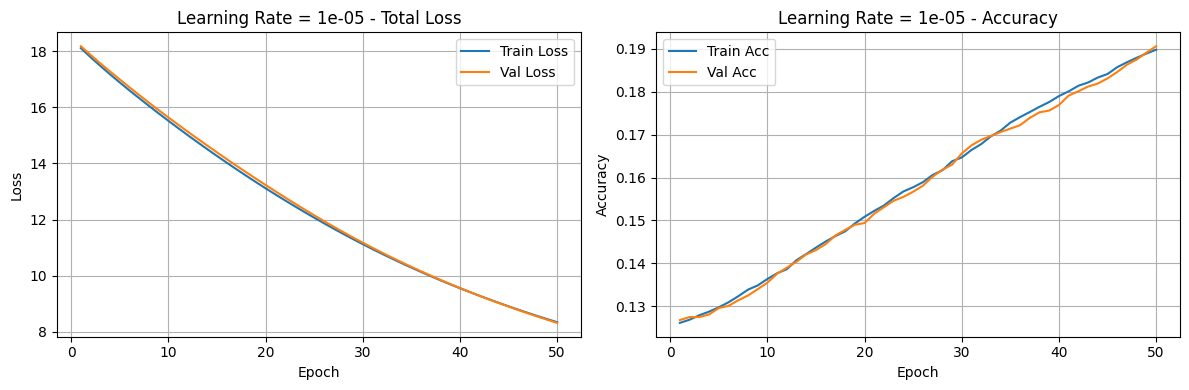

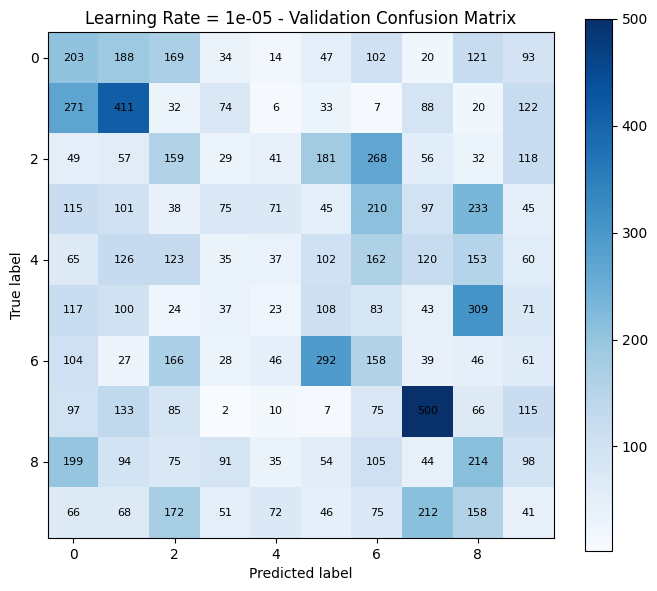

Epoch 01/50 | Train Loss: 5.1742 (CE: 5.1742, L2: 0.0000) | Train Acc: 0.2315 | Val Loss: 5.0820 (CE: 5.0820, L2: 0.0000) | Val Acc: 0.2407
Epoch 02/50 | Train Loss: 3.2217 (CE: 3.2217, L2: 0.0000) | Train Acc: 0.2623 | Val Loss: 3.1257 (CE: 3.1257, L2: 0.0000) | Val Acc: 0.2799
Epoch 03/50 | Train Loss: 2.5976 (CE: 2.5976, L2: 0.0000) | Train Acc: 0.2968 | Val Loss: 2.5128 (CE: 2.5128, L2: 0.0000) | Val Acc: 0.3064
Epoch 04/50 | Train Loss: 2.3161 (CE: 2.3161, L2: 0.0000) | Train Acc: 0.3138 | Val Loss: 2.2390 (CE: 2.2390, L2: 0.0000) | Val Acc: 0.3222
Epoch 05/50 | Train Loss: 2.1599 (CE: 2.1599, L2: 0.0000) | Train Acc: 0.3286 | Val Loss: 2.0906 (CE: 2.0906, L2: 0.0000) | Val Acc: 0.3357
Epoch 06/50 | Train Loss: 2.0615 (CE: 2.0615, L2: 0.0000) | Train Acc: 0.3362 | Val Loss: 1.9966 (CE: 1.9966, L2: 0.0000) | Val Acc: 0.3440
Epoch 07/50 | Train Loss: 1.9916 (CE: 1.9916, L2: 0.0000) | Train Acc: 0.3452 | Val Loss: 1.9291 (CE: 1.9291, L2: 0.0000) | Val Acc: 0.3533
Epoch 08/50 | Train 

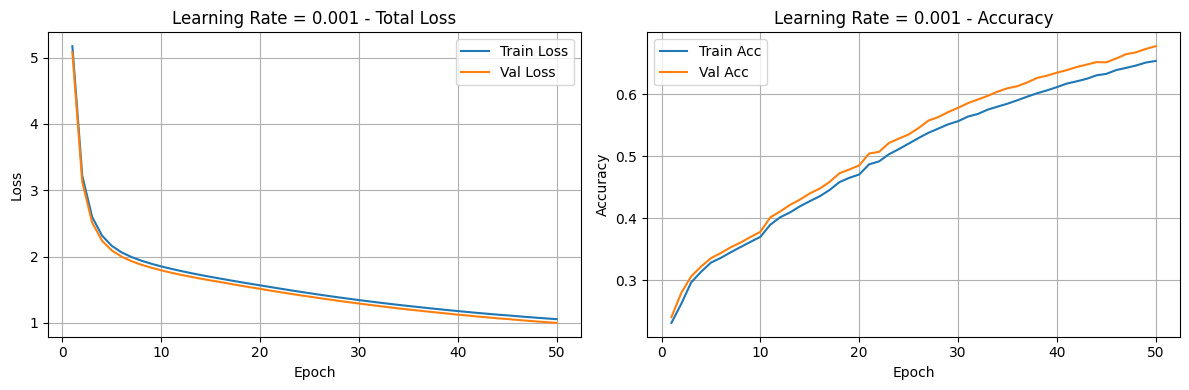

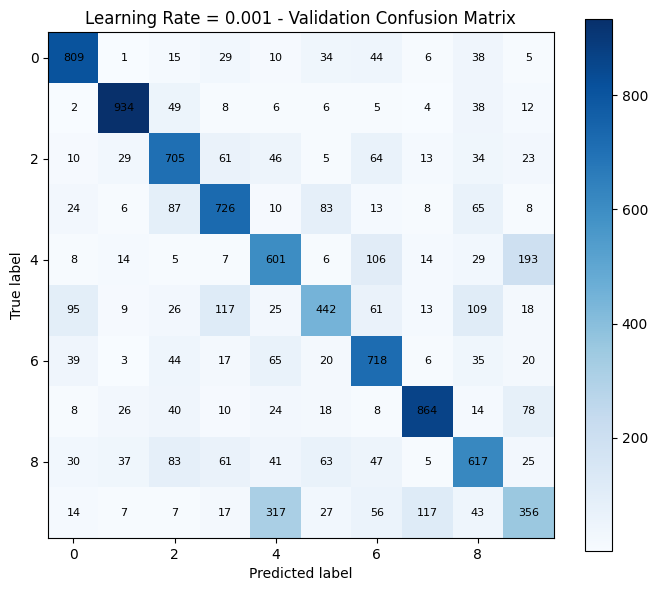

Epoch 01/50 | Train Loss: 1.8531 (CE: 1.8531, L2: 0.0000) | Train Acc: 0.3721 | Val Loss: 1.7930 (CE: 1.7930, L2: 0.0000) | Val Acc: 0.3784
Epoch 02/50 | Train Loss: 1.5650 (CE: 1.5650, L2: 0.0000) | Train Acc: 0.4712 | Val Loss: 1.5120 (CE: 1.5120, L2: 0.0000) | Val Acc: 0.4880
Epoch 03/50 | Train Loss: 1.3397 (CE: 1.3397, L2: 0.0000) | Train Acc: 0.5607 | Val Loss: 1.2883 (CE: 1.2883, L2: 0.0000) | Val Acc: 0.5833
Epoch 04/50 | Train Loss: 1.1881 (CE: 1.1881, L2: 0.0000) | Train Acc: 0.6077 | Val Loss: 1.1346 (CE: 1.1346, L2: 0.0000) | Val Acc: 0.6309
Epoch 05/50 | Train Loss: 1.0611 (CE: 1.0611, L2: 0.0000) | Train Acc: 0.6480 | Val Loss: 1.0084 (CE: 1.0084, L2: 0.0000) | Val Acc: 0.6695
Epoch 06/50 | Train Loss: 0.9708 (CE: 0.9708, L2: 0.0000) | Train Acc: 0.6784 | Val Loss: 0.9155 (CE: 0.9155, L2: 0.0000) | Val Acc: 0.7016
Epoch 07/50 | Train Loss: 0.9012 (CE: 0.9012, L2: 0.0000) | Train Acc: 0.7019 | Val Loss: 0.8475 (CE: 0.8475, L2: 0.0000) | Val Acc: 0.7293
Epoch 08/50 | Train 

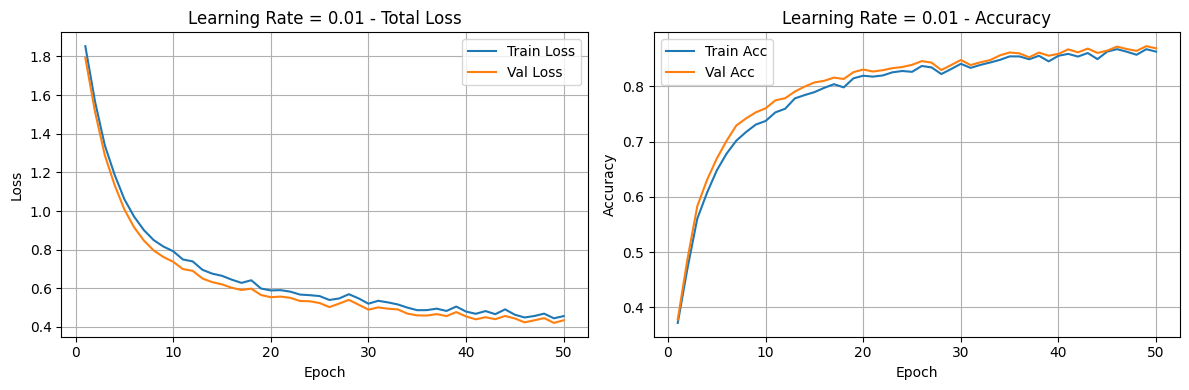

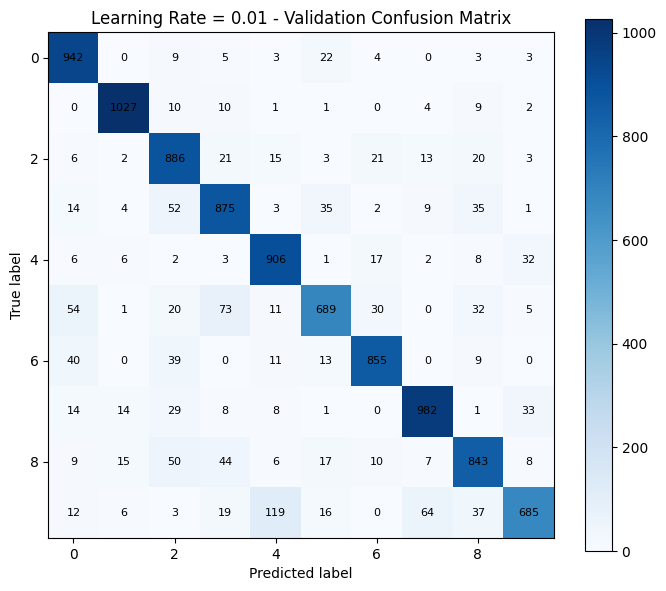

Epoch 01/50 | Train Loss: 0.9168 (CE: 0.9168, L2: 0.0000) | Train Acc: 0.6757 | Val Loss: 0.8921 (CE: 0.8921, L2: 0.0000) | Val Acc: 0.6906
Epoch 02/50 | Train Loss: 0.8006 (CE: 0.8006, L2: 0.0000) | Train Acc: 0.7017 | Val Loss: 0.7764 (CE: 0.7764, L2: 0.0000) | Val Acc: 0.7138
Epoch 03/50 | Train Loss: 0.7562 (CE: 0.7562, L2: 0.0000) | Train Acc: 0.7845 | Val Loss: 0.7273 (CE: 0.7273, L2: 0.0000) | Val Acc: 0.7935
Epoch 04/50 | Train Loss: 0.4744 (CE: 0.4744, L2: 0.0000) | Train Acc: 0.8832 | Val Loss: 0.4694 (CE: 0.4694, L2: 0.0000) | Val Acc: 0.8875
Epoch 05/50 | Train Loss: 0.4938 (CE: 0.4938, L2: 0.0000) | Train Acc: 0.8882 | Val Loss: 0.4774 (CE: 0.4774, L2: 0.0000) | Val Acc: 0.8957
Epoch 06/50 | Train Loss: 0.4454 (CE: 0.4454, L2: 0.0000) | Train Acc: 0.8956 | Val Loss: 0.4290 (CE: 0.4290, L2: 0.0000) | Val Acc: 0.9020
Epoch 07/50 | Train Loss: 0.6846 (CE: 0.6846, L2: 0.0000) | Train Acc: 0.8165 | Val Loss: 0.7128 (CE: 0.7128, L2: 0.0000) | Val Acc: 0.8182
Epoch 08/50 | Train 

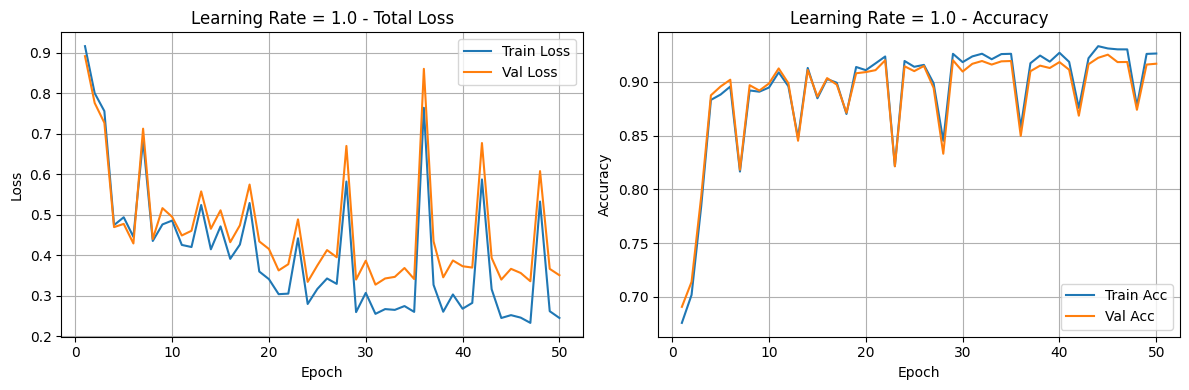

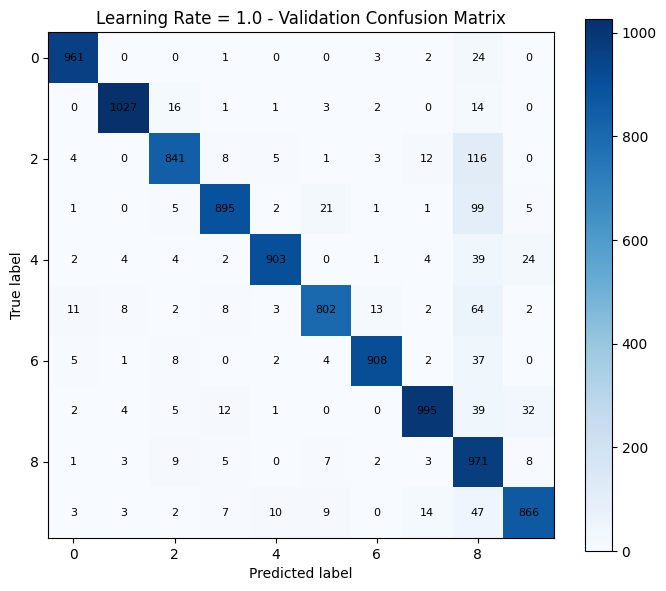

In [13]:
lr_results = {}

for lr in config["search_space"]["learning_rate"]:
    exp_config = copy.deepcopy(selected_config)
    exp_config["train"]["learning_rate"] = lr


    result = run_experiment(
        exp_config,
        x_train, y_train,
        x_val, y_val,
        x_test, y_test,
        exp_name=f"Learning Rate = {lr}",
        early_stopping=False
    )

    lr_results[f"lr={lr}"] = result

In [20]:
print("Learning-rate comparison:")
print("-" * 60)
print(f"{'Experiment':<12} {'Train Loss':<12} {'Train Acc':<12} {'Val Loss':<12} {'Val Acc':<12}")
print("-" * 60)

for name, result in lr_results.items():
    print(
        f"{name:<12} "
        f"{result['train_loss']:<12.4f}"
        f"{result['train_acc']:<12.4f}"
        f"{result['val_loss']:<12.4f} "
        f"{result['val_acc']:<12.4f}"
    )

Learning-rate comparison:
------------------------------------------------------------
Experiment   Train Loss   Train Acc    Val Loss     Val Acc     
------------------------------------------------------------
lr=1e-05     8.3461      0.1898      8.3214       0.1906      
lr=0.001     1.0555      0.6534      0.9994       0.6772      
lr=0.01      0.4563      0.8630      0.4346       0.8690      
lr=1.0       0.2448      0.9264      0.3505       0.9169      
lr=0.005     0.5490      0.8341      0.5173       0.8399      


In [198]:
selected_config["train"]["learning_rate"] = 0.01

## Q2.9

Epoch 01/50 | Train Loss: 18.1039 | Train Acc: 0.1261 | Val Loss: 18.1749 | Val Acc: 0.1268
Epoch 02/50 | Train Loss: 17.7834 | Train Acc: 0.1269 | Val Loss: 17.8634 | Val Acc: 0.1275
Epoch 03/50 | Train Loss: 17.4741 | Train Acc: 0.1279 | Val Loss: 17.5643 | Val Acc: 0.1275
Epoch 04/50 | Train Loss: 17.1741 | Train Acc: 0.1288 | Val Loss: 17.2745 | Val Acc: 0.1281
Epoch 05/50 | Train Loss: 16.8825 | Train Acc: 0.1298 | Val Loss: 16.9911 | Val Acc: 0.1296
Epoch 06/50 | Train Loss: 16.5995 | Train Acc: 0.1309 | Val Loss: 16.7114 | Val Acc: 0.1301
Epoch 07/50 | Train Loss: 16.3227 | Train Acc: 0.1323 | Val Loss: 16.4352 | Val Acc: 0.1314
Epoch 08/50 | Train Loss: 16.0505 | Train Acc: 0.1339 | Val Loss: 16.1646 | Val Acc: 0.1325
Epoch 09/50 | Train Loss: 15.7826 | Train Acc: 0.1349 | Val Loss: 15.8992 | Val Acc: 0.1340
Epoch 10/50 | Train Loss: 15.5195 | Train Acc: 0.1364 | Val Loss: 15.6387 | Val Acc: 0.1355
Epoch 11/50 | Train Loss: 15.2607 | Train Acc: 0.1377 | Val Loss: 15.3823 | Val 

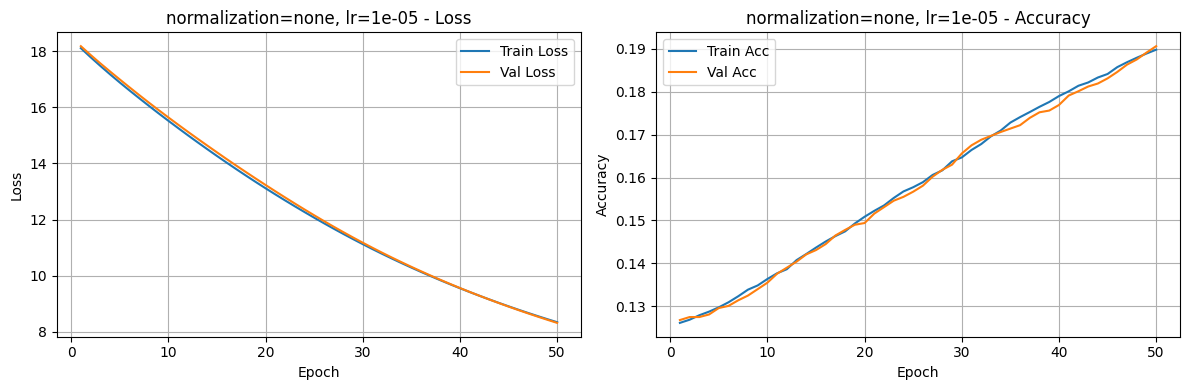

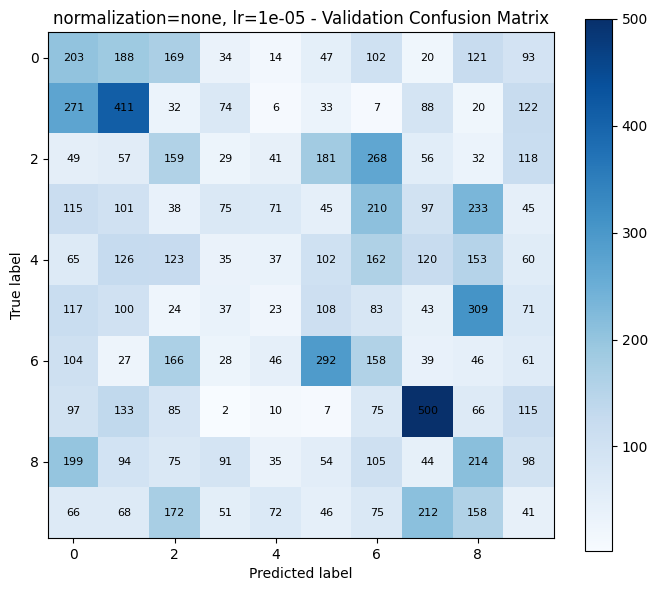

Epoch 01/50 | Train Loss: 1.8531 | Train Acc: 0.3721 | Val Loss: 1.7930 | Val Acc: 0.3784
Epoch 02/50 | Train Loss: 1.5650 | Train Acc: 0.4712 | Val Loss: 1.5120 | Val Acc: 0.4880
Epoch 03/50 | Train Loss: 1.3397 | Train Acc: 0.5607 | Val Loss: 1.2883 | Val Acc: 0.5833
Epoch 04/50 | Train Loss: 1.1881 | Train Acc: 0.6077 | Val Loss: 1.1346 | Val Acc: 0.6309
Epoch 05/50 | Train Loss: 1.0611 | Train Acc: 0.6480 | Val Loss: 1.0084 | Val Acc: 0.6695
Epoch 06/50 | Train Loss: 0.9708 | Train Acc: 0.6784 | Val Loss: 0.9155 | Val Acc: 0.7016
Epoch 07/50 | Train Loss: 0.9012 | Train Acc: 0.7019 | Val Loss: 0.8475 | Val Acc: 0.7293
Epoch 08/50 | Train Loss: 0.8497 | Train Acc: 0.7175 | Val Loss: 0.7961 | Val Acc: 0.7422
Epoch 09/50 | Train Loss: 0.8162 | Train Acc: 0.7311 | Val Loss: 0.7621 | Val Acc: 0.7532
Epoch 10/50 | Train Loss: 0.7920 | Train Acc: 0.7374 | Val Loss: 0.7374 | Val Acc: 0.7604
Epoch 11/50 | Train Loss: 0.7493 | Train Acc: 0.7531 | Val Loss: 0.6995 | Val Acc: 0.7748
Epoch 12/5

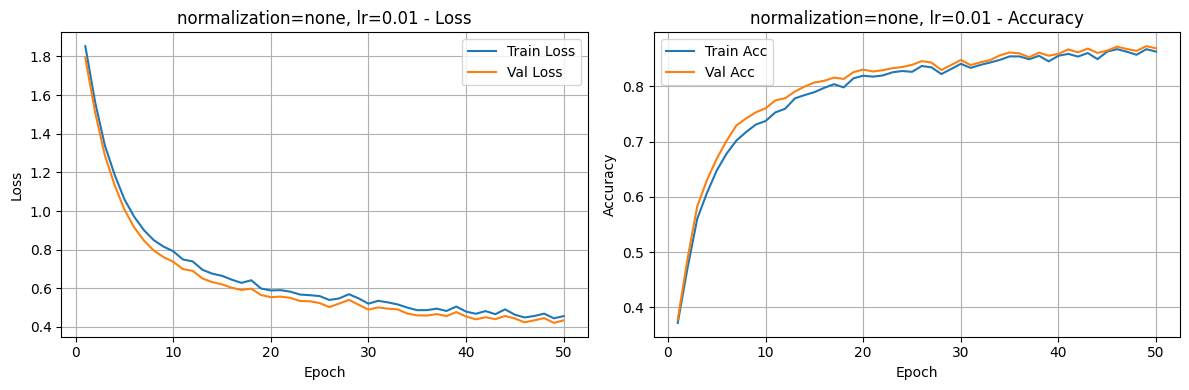

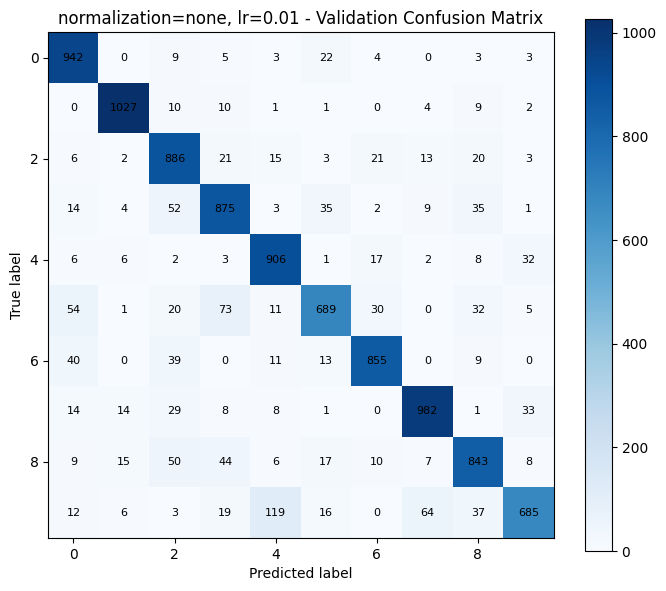

Epoch 01/50 | Train Loss: 0.9168 | Train Acc: 0.6757 | Val Loss: 0.8921 | Val Acc: 0.6906
Epoch 02/50 | Train Loss: 0.8006 | Train Acc: 0.7017 | Val Loss: 0.7764 | Val Acc: 0.7138
Epoch 03/50 | Train Loss: 0.7562 | Train Acc: 0.7845 | Val Loss: 0.7273 | Val Acc: 0.7935
Epoch 04/50 | Train Loss: 0.4744 | Train Acc: 0.8832 | Val Loss: 0.4694 | Val Acc: 0.8875
Epoch 05/50 | Train Loss: 0.4938 | Train Acc: 0.8882 | Val Loss: 0.4774 | Val Acc: 0.8957
Epoch 06/50 | Train Loss: 0.4454 | Train Acc: 0.8956 | Val Loss: 0.4290 | Val Acc: 0.9020
Epoch 07/50 | Train Loss: 0.6846 | Train Acc: 0.8165 | Val Loss: 0.7128 | Val Acc: 0.8182
Epoch 08/50 | Train Loss: 0.4352 | Train Acc: 0.8920 | Val Loss: 0.4399 | Val Acc: 0.8969
Epoch 09/50 | Train Loss: 0.4761 | Train Acc: 0.8908 | Val Loss: 0.5164 | Val Acc: 0.8919
Epoch 10/50 | Train Loss: 0.4856 | Train Acc: 0.8947 | Val Loss: 0.4948 | Val Acc: 0.8985
Epoch 11/50 | Train Loss: 0.4254 | Train Acc: 0.9088 | Val Loss: 0.4488 | Val Acc: 0.9125
Epoch 12/5

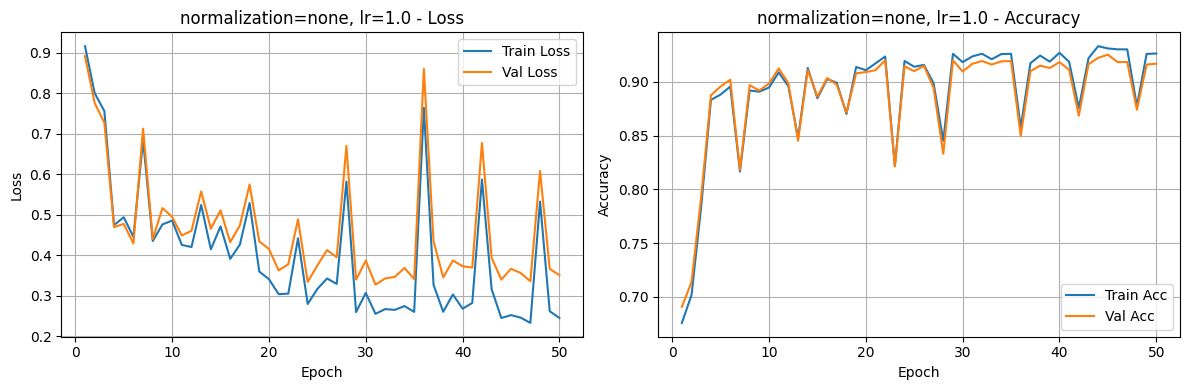

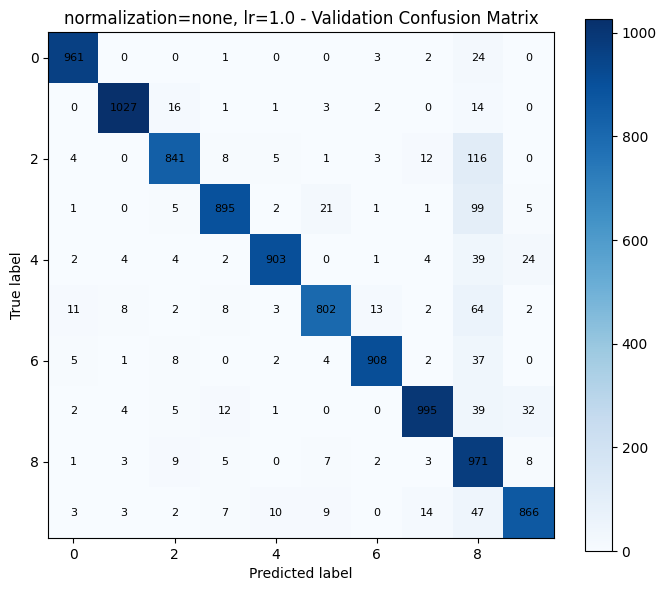

Epoch 01/50 | Train Loss: 22.0245 | Train Acc: 0.1352 | Val Loss: 22.1101 | Val Acc: 0.1372
Epoch 02/50 | Train Loss: 21.7897 | Train Acc: 0.1406 | Val Loss: 21.8632 | Val Acc: 0.1421
Epoch 03/50 | Train Loss: 21.5645 | Train Acc: 0.1467 | Val Loss: 21.6275 | Val Acc: 0.1473
Epoch 04/50 | Train Loss: 21.3452 | Train Acc: 0.1526 | Val Loss: 21.4049 | Val Acc: 0.1523
Epoch 05/50 | Train Loss: 21.1260 | Train Acc: 0.1576 | Val Loss: 21.1837 | Val Acc: 0.1572
Epoch 06/50 | Train Loss: 20.9088 | Train Acc: 0.1628 | Val Loss: 20.9620 | Val Acc: 0.1612
Epoch 07/50 | Train Loss: 20.6945 | Train Acc: 0.1669 | Val Loss: 20.7405 | Val Acc: 0.1662
Epoch 08/50 | Train Loss: 20.4808 | Train Acc: 0.1712 | Val Loss: 20.5177 | Val Acc: 0.1716
Epoch 09/50 | Train Loss: 20.2677 | Train Acc: 0.1750 | Val Loss: 20.3000 | Val Acc: 0.1758
Epoch 10/50 | Train Loss: 20.0562 | Train Acc: 0.1790 | Val Loss: 20.0867 | Val Acc: 0.1809
Epoch 11/50 | Train Loss: 19.8434 | Train Acc: 0.1832 | Val Loss: 19.8701 | Val 

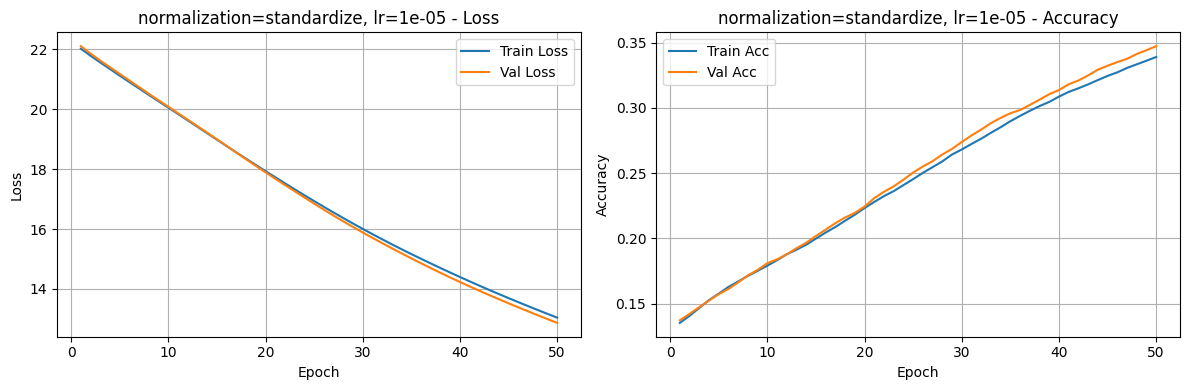

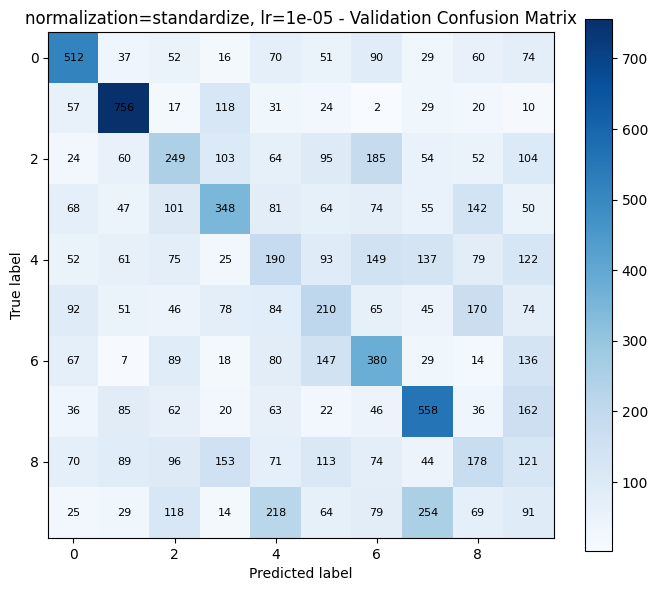

Epoch 01/50 | Train Loss: 1.9419 | Train Acc: 0.4952 | Val Loss: 1.8450 | Val Acc: 0.5110
Epoch 02/50 | Train Loss: 3.1557 | Train Acc: 0.3897 | Val Loss: 3.0481 | Val Acc: 0.3956
Epoch 03/50 | Train Loss: 1.6324 | Train Acc: 0.5734 | Val Loss: 1.5586 | Val Acc: 0.5841
Epoch 04/50 | Train Loss: 1.7019 | Train Acc: 0.5732 | Val Loss: 1.6517 | Val Acc: 0.5843
Epoch 05/50 | Train Loss: 1.4337 | Train Acc: 0.5988 | Val Loss: 1.3705 | Val Acc: 0.6031
Epoch 06/50 | Train Loss: 1.3551 | Train Acc: 0.6426 | Val Loss: 1.2944 | Val Acc: 0.6559
Epoch 07/50 | Train Loss: 1.2647 | Train Acc: 0.6549 | Val Loss: 1.1808 | Val Acc: 0.6627
Epoch 08/50 | Train Loss: 1.1732 | Train Acc: 0.7024 | Val Loss: 1.0838 | Val Acc: 0.7190
Epoch 09/50 | Train Loss: 1.1208 | Train Acc: 0.7121 | Val Loss: 1.0466 | Val Acc: 0.7186
Epoch 10/50 | Train Loss: 1.0802 | Train Acc: 0.7041 | Val Loss: 1.0050 | Val Acc: 0.7205
Epoch 11/50 | Train Loss: 1.2390 | Train Acc: 0.6877 | Val Loss: 1.1668 | Val Acc: 0.6948
Epoch 12/5

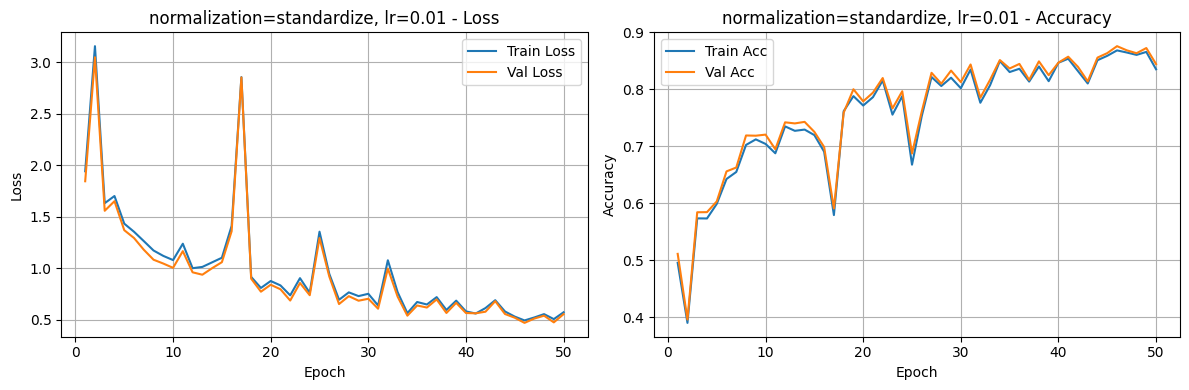

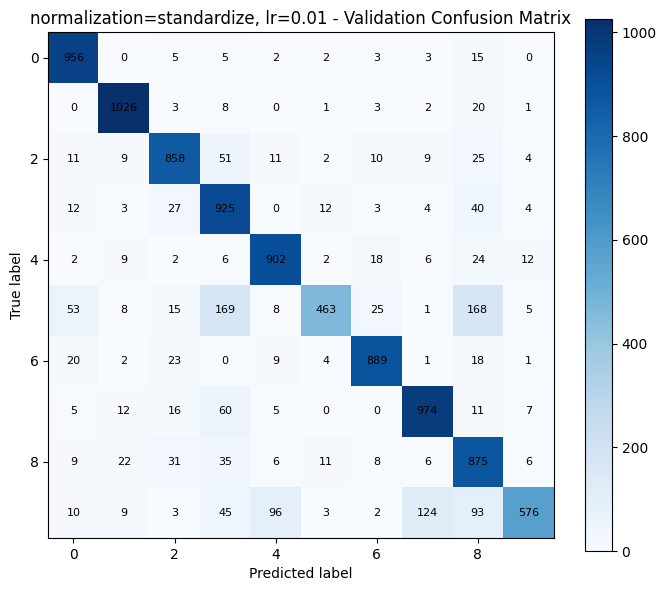

C:\Users\ASUS\AppData\Local\Temp\ipykernel_20788\2181030468.py:51: RuntimeWarning: overflow encountered in matmul
  ZL = A @ self.params[f"W{self.num_layers}"] + self.params[f"b{self.num_layers}"]
C:\Users\ASUS\AppData\Local\Temp\ipykernel_20788\755445621.py:10: RuntimeWarning: overflow encountered in subtract
  x_shifted = x - np.max(x, axis=1, keepdims=True)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_20788\755445621.py:10: RuntimeWarning: invalid value encountered in subtract
  x_shifted = x - np.max(x, axis=1, keepdims=True)


Epoch 01/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc: 0.0991
Epoch 02/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc: 0.0991
Epoch 03/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc: 0.0991
Epoch 04/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc: 0.0991
Epoch 05/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc: 0.0991
Epoch 06/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc: 0.0991
Epoch 07/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc: 0.0991
Epoch 08/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc: 0.0991
Epoch 09/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc: 0.0991
Epoch 10/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc: 0.0991
Epoch 11/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc: 0.0991
Epoch 12/50 | Train Loss: nan | Train Acc: 0.0986 | Val Loss: nan | Val Acc:

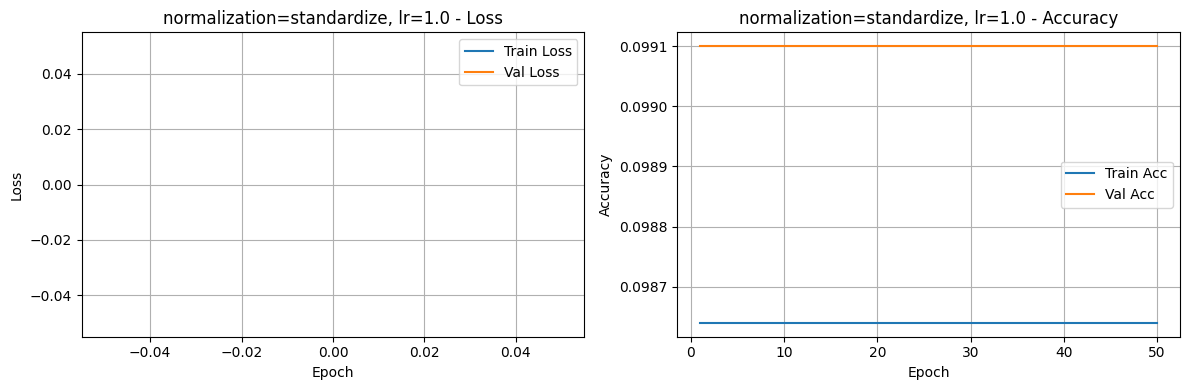

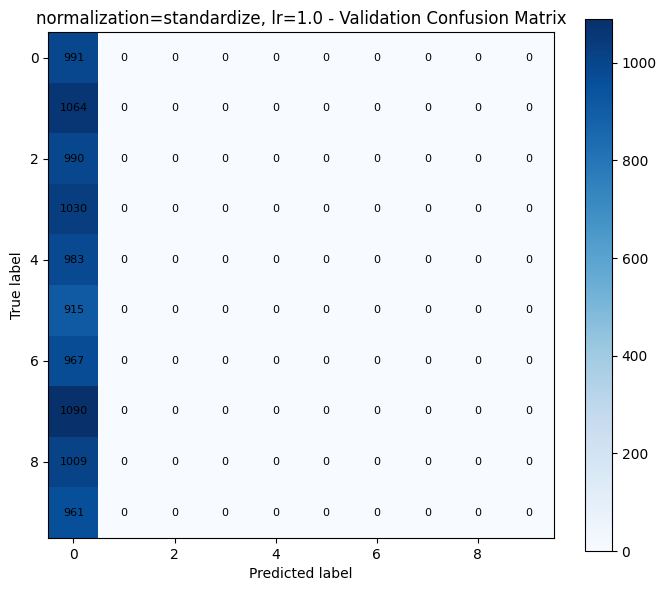

In [ ]:
normalization_results = {}

for norm in config["search_space"]["normalization"]:
    normalization_results[norm] = {}

    for lr in config["search_space"]["learning_rate"]:
        exp_config = copy.deepcopy(selected_config)
        exp_config["train"]["learning_rate"] = lr
        exp_config["preprocessing"]["normalization"] = norm

        result = run_experiment(
            exp_config,
            x_train, y_train,
            x_val, y_val,
            x_test, y_test,
            exp_name=f"normalization={norm}, lr={lr}",
            early_stopping=False
        )

        normalization_results[norm][lr] = result

In [ ]:
print("Normalization + learning-rate comparison:")
print("-" * 95)
print(f"{'Normalization':<18} {'LR':<10} {'Train Loss':<12} {'Train Acc':<12} {'Val Loss':<12} {'Val Acc':<12}")
print("-" * 95)

for norm, lr_dict in normalization_results.items():
    for lr, result in lr_dict.items():
        print(
            f"{str(norm):<18} "
            f"{str(lr):<10} "
            f"{result['train_loss']:<12.4f}"
            f"{result['train_acc']:<12.4f}"
            f"{result['val_loss']:<12.4f}"
            f"{result['val_acc']:<12.4f}"
        )

Normalization + learning-rate comparison:
-----------------------------------------------------------------------------------------------
Normalization      LR         Train Loss   Train Acc    Val Loss     Val Acc     
-----------------------------------------------------------------------------------------------
none               1e-05      8.3461      0.1898      8.3214      0.1906      
none               0.01       0.4563      0.8630      0.4346      0.8690      
none               1.0        0.2448      0.9264      0.3505      0.9169      
standardize        1e-05      13.0416     0.3389      12.8664     0.3472      
standardize        0.01       0.5737      0.8353      0.5557      0.8444      
standardize        1.0        nan         0.0986      nan         0.0991      


In [199]:
selected_config["preprocessing"]["normalization"] = "none"
selected_config["train"]["learning_rate"] = 0.01

## Q2.10

Epoch 01/50 | Train Loss: 1.2380 (CE: 1.2380, L2: 0.0000) | Train Acc: 0.5895 | Val Loss: 1.1798 (CE: 1.1798, L2: 0.0000) | Val Acc: 0.6137
Epoch 02/50 | Train Loss: 0.8935 (CE: 0.8935, L2: 0.0000) | Train Acc: 0.7042 | Val Loss: 0.8454 (CE: 0.8454, L2: 0.0000) | Val Acc: 0.7254
Epoch 03/50 | Train Loss: 0.7601 (CE: 0.7601, L2: 0.0000) | Train Acc: 0.7497 | Val Loss: 0.7223 (CE: 0.7223, L2: 0.0000) | Val Acc: 0.7686
Epoch 04/50 | Train Loss: 0.6732 (CE: 0.6732, L2: 0.0000) | Train Acc: 0.7877 | Val Loss: 0.6325 (CE: 0.6325, L2: 0.0000) | Val Acc: 0.8034
Epoch 05/50 | Train Loss: 0.6551 (CE: 0.6551, L2: 0.0000) | Train Acc: 0.7971 | Val Loss: 0.6228 (CE: 0.6228, L2: 0.0000) | Val Acc: 0.8055
Epoch 06/50 | Train Loss: 0.6024 (CE: 0.6024, L2: 0.0000) | Train Acc: 0.8150 | Val Loss: 0.5625 (CE: 0.5625, L2: 0.0000) | Val Acc: 0.8247
Epoch 07/50 | Train Loss: 0.5827 (CE: 0.5827, L2: 0.0000) | Train Acc: 0.8196 | Val Loss: 0.5519 (CE: 0.5519, L2: 0.0000) | Val Acc: 0.8255
Epoch 08/50 | Train 

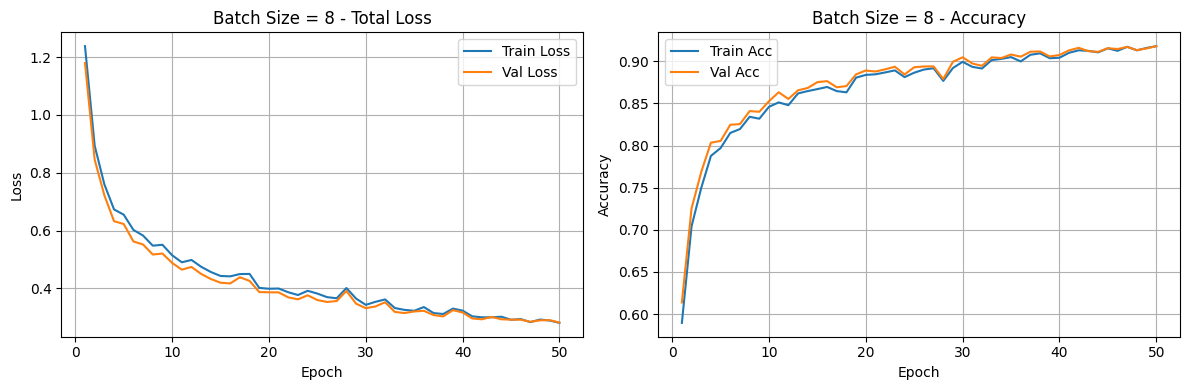

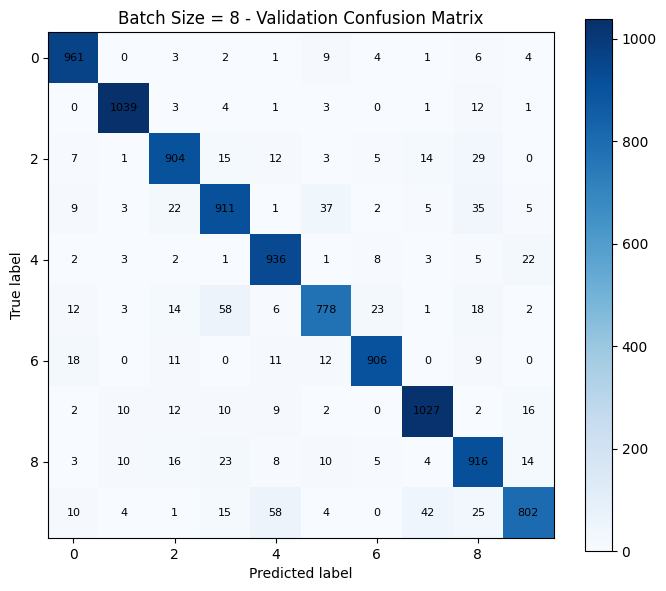

Epoch 01/50 | Train Loss: 1.5749 (CE: 1.5749, L2: 0.0000) | Train Acc: 0.4734 | Val Loss: 1.5188 (CE: 1.5188, L2: 0.0000) | Val Acc: 0.4933
Epoch 02/50 | Train Loss: 1.1906 (CE: 1.1906, L2: 0.0000) | Train Acc: 0.6030 | Val Loss: 1.1409 (CE: 1.1409, L2: 0.0000) | Val Acc: 0.6205
Epoch 03/50 | Train Loss: 0.9845 (CE: 0.9845, L2: 0.0000) | Train Acc: 0.6697 | Val Loss: 0.9349 (CE: 0.9349, L2: 0.0000) | Val Acc: 0.6955
Epoch 04/50 | Train Loss: 0.8678 (CE: 0.8678, L2: 0.0000) | Train Acc: 0.7113 | Val Loss: 0.8129 (CE: 0.8129, L2: 0.0000) | Val Acc: 0.7385
Epoch 05/50 | Train Loss: 0.8070 (CE: 0.8070, L2: 0.0000) | Train Acc: 0.7352 | Val Loss: 0.7637 (CE: 0.7637, L2: 0.0000) | Val Acc: 0.7525
Epoch 06/50 | Train Loss: 0.7308 (CE: 0.7308, L2: 0.0000) | Train Acc: 0.7642 | Val Loss: 0.6805 (CE: 0.6805, L2: 0.0000) | Val Acc: 0.7824
Epoch 07/50 | Train Loss: 0.6900 (CE: 0.6900, L2: 0.0000) | Train Acc: 0.7784 | Val Loss: 0.6464 (CE: 0.6464, L2: 0.0000) | Val Acc: 0.7930
Epoch 08/50 | Train 

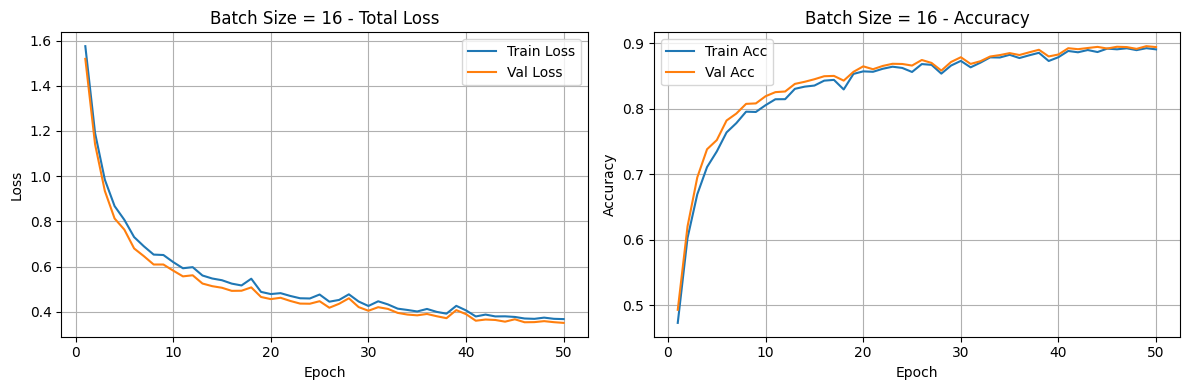

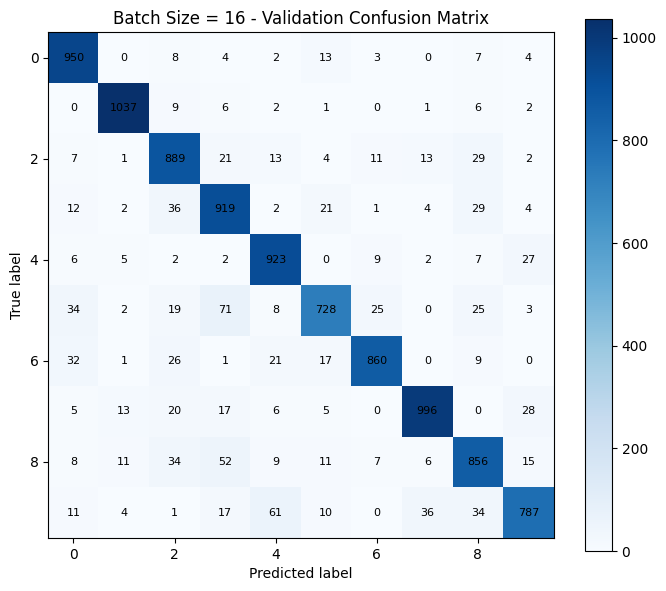

Epoch 01/50 | Train Loss: 1.8531 (CE: 1.8531, L2: 0.0000) | Train Acc: 0.3721 | Val Loss: 1.7930 (CE: 1.7930, L2: 0.0000) | Val Acc: 0.3784
Epoch 02/50 | Train Loss: 1.5650 (CE: 1.5650, L2: 0.0000) | Train Acc: 0.4712 | Val Loss: 1.5120 (CE: 1.5120, L2: 0.0000) | Val Acc: 0.4880
Epoch 03/50 | Train Loss: 1.3397 (CE: 1.3397, L2: 0.0000) | Train Acc: 0.5607 | Val Loss: 1.2883 (CE: 1.2883, L2: 0.0000) | Val Acc: 0.5833
Epoch 04/50 | Train Loss: 1.1881 (CE: 1.1881, L2: 0.0000) | Train Acc: 0.6077 | Val Loss: 1.1346 (CE: 1.1346, L2: 0.0000) | Val Acc: 0.6309
Epoch 05/50 | Train Loss: 1.0611 (CE: 1.0611, L2: 0.0000) | Train Acc: 0.6480 | Val Loss: 1.0084 (CE: 1.0084, L2: 0.0000) | Val Acc: 0.6695
Epoch 06/50 | Train Loss: 0.9708 (CE: 0.9708, L2: 0.0000) | Train Acc: 0.6784 | Val Loss: 0.9155 (CE: 0.9155, L2: 0.0000) | Val Acc: 0.7016
Epoch 07/50 | Train Loss: 0.9012 (CE: 0.9012, L2: 0.0000) | Train Acc: 0.7019 | Val Loss: 0.8475 (CE: 0.8475, L2: 0.0000) | Val Acc: 0.7293
Epoch 08/50 | Train 

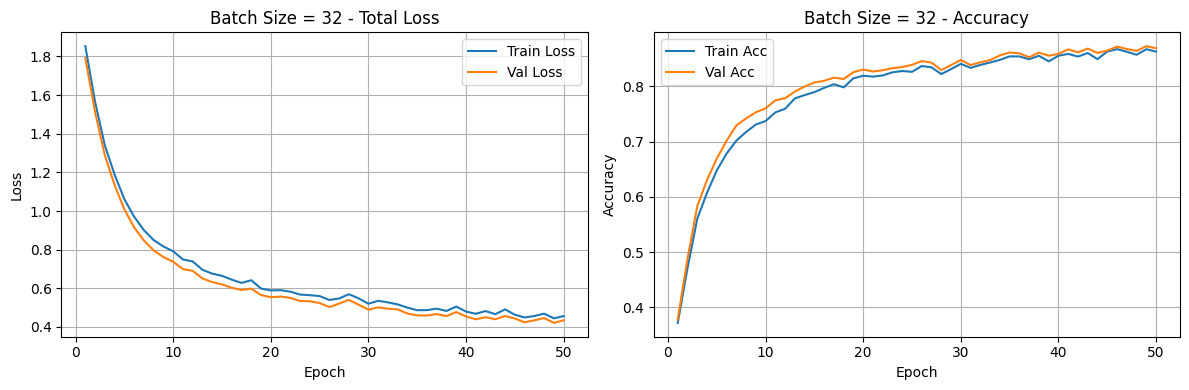

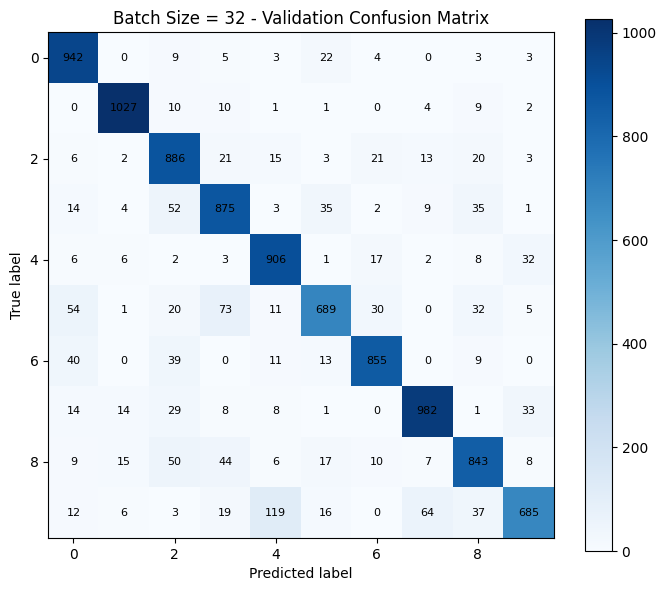

Epoch 01/50 | Train Loss: 2.8413 (CE: 2.8413, L2: 0.0000) | Train Acc: 0.2842 | Val Loss: 2.7504 (CE: 2.7504, L2: 0.0000) | Val Acc: 0.2973
Epoch 02/50 | Train Loss: 2.1575 (CE: 2.1575, L2: 0.0000) | Train Acc: 0.3275 | Val Loss: 2.0875 (CE: 2.0875, L2: 0.0000) | Val Acc: 0.3363
Epoch 03/50 | Train Loss: 1.9598 (CE: 1.9598, L2: 0.0000) | Train Acc: 0.3525 | Val Loss: 1.8979 (CE: 1.8979, L2: 0.0000) | Val Acc: 0.3602
Epoch 04/50 | Train Loss: 1.8483 (CE: 1.8483, L2: 0.0000) | Train Acc: 0.3731 | Val Loss: 1.7892 (CE: 1.7892, L2: 0.0000) | Val Acc: 0.3822
Epoch 05/50 | Train Loss: 1.7630 (CE: 1.7630, L2: 0.0000) | Train Acc: 0.4082 | Val Loss: 1.7076 (CE: 1.7076, L2: 0.0000) | Val Acc: 0.4159
Epoch 06/50 | Train Loss: 1.6909 (CE: 1.6909, L2: 0.0000) | Train Acc: 0.4318 | Val Loss: 1.6368 (CE: 1.6368, L2: 0.0000) | Val Acc: 0.4443
Epoch 07/50 | Train Loss: 1.6249 (CE: 1.6249, L2: 0.0000) | Train Acc: 0.4563 | Val Loss: 1.5719 (CE: 1.5719, L2: 0.0000) | Val Acc: 0.4699
Epoch 08/50 | Train 

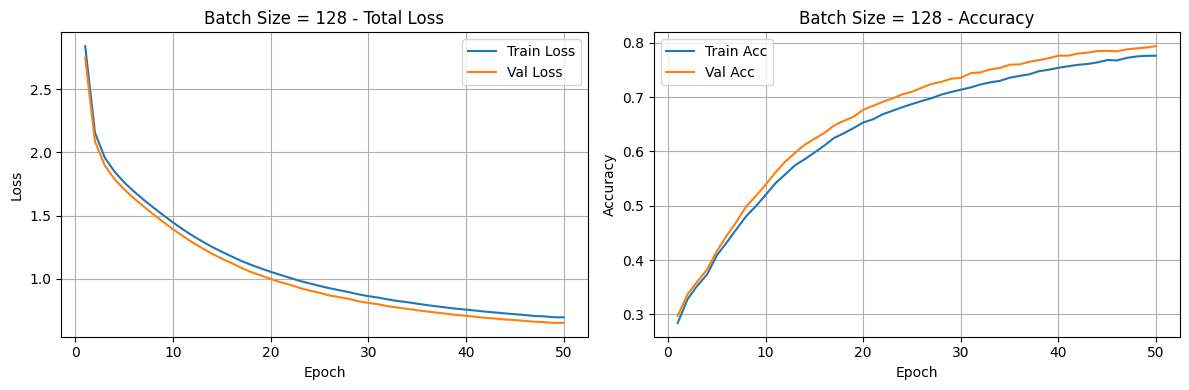

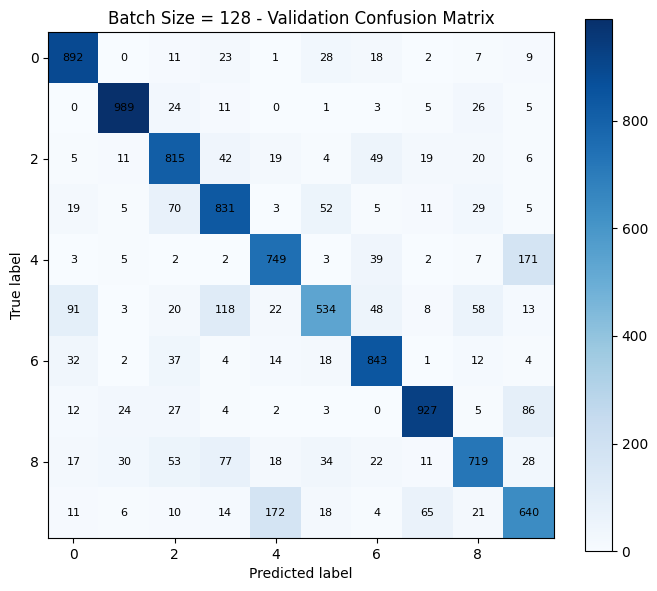

In [32]:
bs_results = {}

for bs in config["search_space"]["batch_size"]:
    exp_config = copy.deepcopy(selected_config)
    exp_config["train"]["batch_size"] = bs

    result = run_experiment(
        exp_config,
        x_train, y_train,
        x_val, y_val,
        x_test, y_test,
        exp_name=f"Batch Size = {bs}",
        early_stopping=False
    )

    bs_results[f"bs={bs}"] = result


In [35]:
print("Batch-Size comparison:")
print("-" * 70)
print(f"{'Experiment':<20} {'Train Loss':<12} {'Train Acc':<12} {'Val Loss':<12} {'Val Acc':<12}")
print("-" * 70)

for name, result in bs_results.items():
    print(
        f"{name:<20} "
        f"{result['train_loss']:<12.4f}"
        f"{result['train_acc']:<12.4f}"
        f"{result['val_loss']:<12.4f} "
        f"{result['val_acc']:<12.4f}"
    )

Batch-Size comparison:
----------------------------------------------------------------------
Experiment           Train Loss   Train Acc    Val Loss     Val Acc     
----------------------------------------------------------------------
bs=8                 0.2808      0.9180      0.2819       0.9180      
bs=16                0.3682      0.8910      0.3515       0.8945      
bs=32                0.4563      0.8630      0.4346       0.8690      
bs=128               0.6955      0.7763      0.6516       0.7939      


In [200]:
selected_config["train"]["batch_size"] = 8

## Q2.11

Epoch 01/50 | Train Loss: 1.2380 (CE: 1.2380, L2: 0.0000) | Train Acc: 0.5895 | Val Loss: 1.1798 (CE: 1.1798, L2: 0.0000) | Val Acc: 0.6137
Epoch 02/50 | Train Loss: 0.8935 (CE: 0.8935, L2: 0.0000) | Train Acc: 0.7042 | Val Loss: 0.8454 (CE: 0.8454, L2: 0.0000) | Val Acc: 0.7254
Epoch 03/50 | Train Loss: 0.7601 (CE: 0.7601, L2: 0.0000) | Train Acc: 0.7497 | Val Loss: 0.7223 (CE: 0.7223, L2: 0.0000) | Val Acc: 0.7686
Epoch 04/50 | Train Loss: 0.6732 (CE: 0.6732, L2: 0.0000) | Train Acc: 0.7877 | Val Loss: 0.6325 (CE: 0.6325, L2: 0.0000) | Val Acc: 0.8034
Epoch 05/50 | Train Loss: 0.6551 (CE: 0.6551, L2: 0.0000) | Train Acc: 0.7971 | Val Loss: 0.6228 (CE: 0.6228, L2: 0.0000) | Val Acc: 0.8055
Epoch 06/50 | Train Loss: 0.6024 (CE: 0.6024, L2: 0.0000) | Train Acc: 0.8150 | Val Loss: 0.5625 (CE: 0.5625, L2: 0.0000) | Val Acc: 0.8247
Epoch 07/50 | Train Loss: 0.5827 (CE: 0.5827, L2: 0.0000) | Train Acc: 0.8196 | Val Loss: 0.5519 (CE: 0.5519, L2: 0.0000) | Val Acc: 0.8255
Epoch 08/50 | Train 

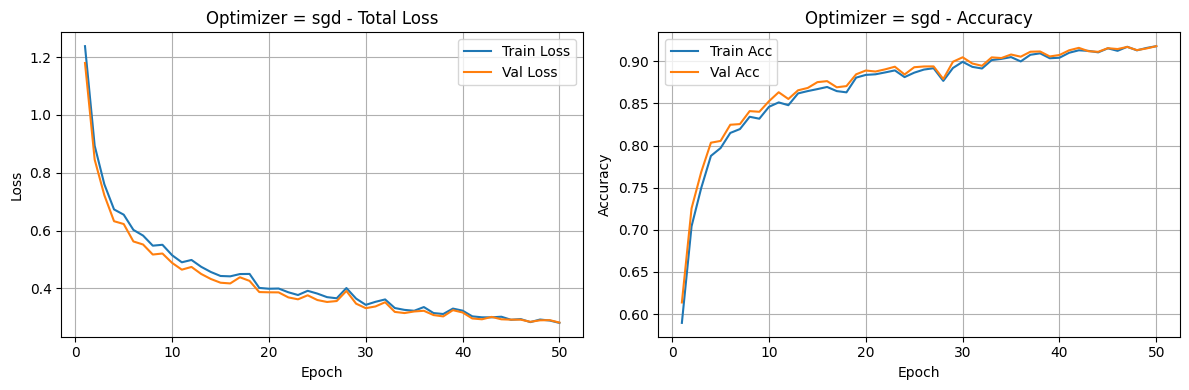

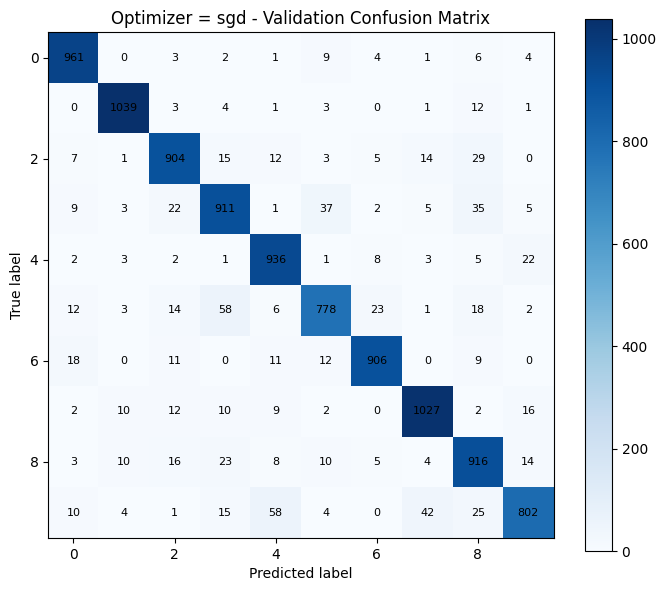

Epoch 01/50 | Train Loss: 0.5561 (CE: 0.5561, L2: 0.0000) | Train Acc: 0.8428 | Val Loss: 0.5326 (CE: 0.5326, L2: 0.0000) | Val Acc: 0.8519
Epoch 02/50 | Train Loss: 0.4515 (CE: 0.4515, L2: 0.0000) | Train Acc: 0.8783 | Val Loss: 0.4474 (CE: 0.4474, L2: 0.0000) | Val Acc: 0.8814
Epoch 03/50 | Train Loss: 0.4420 (CE: 0.4420, L2: 0.0000) | Train Acc: 0.8802 | Val Loss: 0.4468 (CE: 0.4468, L2: 0.0000) | Val Acc: 0.8846
Epoch 04/50 | Train Loss: 0.3336 (CE: 0.3336, L2: 0.0000) | Train Acc: 0.9072 | Val Loss: 0.3487 (CE: 0.3487, L2: 0.0000) | Val Acc: 0.9071
Epoch 05/50 | Train Loss: 0.3071 (CE: 0.3071, L2: 0.0000) | Train Acc: 0.9164 | Val Loss: 0.3240 (CE: 0.3240, L2: 0.0000) | Val Acc: 0.9152
Epoch 06/50 | Train Loss: 0.2940 (CE: 0.2940, L2: 0.0000) | Train Acc: 0.9193 | Val Loss: 0.3182 (CE: 0.3182, L2: 0.0000) | Val Acc: 0.9170
Epoch 07/50 | Train Loss: 0.2815 (CE: 0.2815, L2: 0.0000) | Train Acc: 0.9211 | Val Loss: 0.3074 (CE: 0.3074, L2: 0.0000) | Val Acc: 0.9182
Epoch 08/50 | Train 

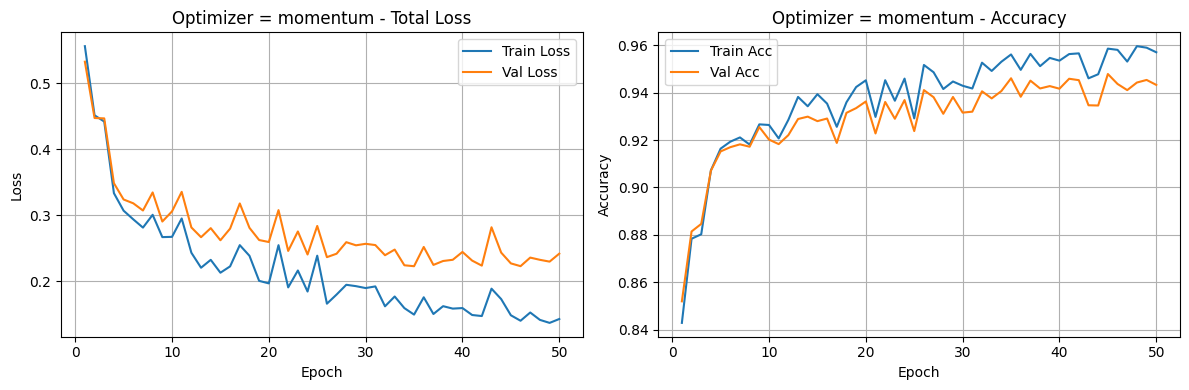

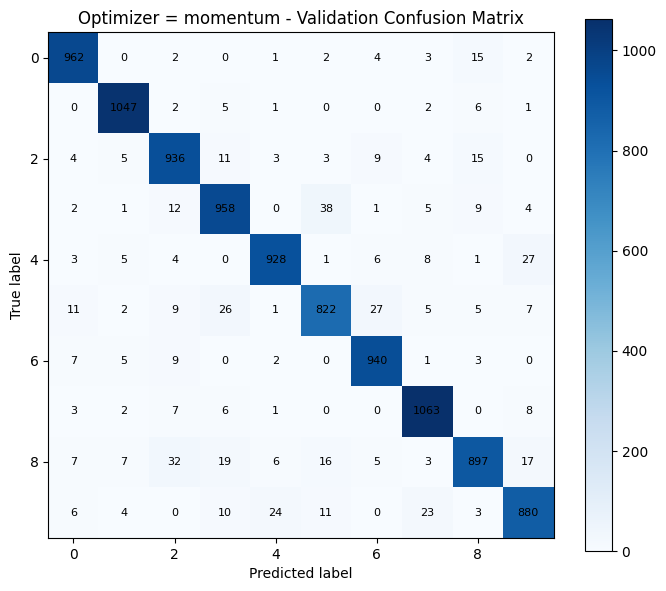

In [39]:
opt_results = {}

for opt in config["search_space"]["optimizer"]:
    exp_config = copy.deepcopy(selected_config)
    exp_config["train"]["optimizer"] = opt

    result = run_experiment(
        exp_config,
        x_train, y_train,
        x_val, y_val,
        x_test, y_test,
        exp_name=f"Optimizer = {opt}"
    )

    opt_results[f"opt = {opt}"] = result

In [45]:
print("Optimizer comparison:")
print("-" * 80)
print(f"{'Experiment':25} {'Train Loss':<12} {'Train Acc':<12} {'Val Loss':<12} {'Val Acc':<12}")
print("-" * 80)

for name, result in opt_results.items():
    print(
        f"{name:<25} "
        f"{result['train_loss']:<12.4f}"
        f"{result['train_acc']:<12.4f}"
        f"{result['val_loss']:<12.4f} "
        f"{result['val_acc']:<12.4f}"
    )

Optimizer comparison:
--------------------------------------------------------------------------------
Experiment                Train Loss   Train Acc    Val Loss     Val Acc     
--------------------------------------------------------------------------------
opt = sgd                 0.2808      0.9180      0.2819       0.9180      
opt = momentum            0.1431      0.9571      0.2420       0.9433      


In [201]:
selected_config["train"]["optimizer"] = "momentum"

## Q2.12 , Q2.13

Epoch 01/50 | Train Loss: 0.9291 (CE: 0.9291, L2: 0.0000) | Train Acc: 0.6513 | Val Loss: 0.9012 (CE: 0.9012, L2: 0.0000) | Val Acc: 0.6572
Epoch 02/50 | Train Loss: 0.6650 (CE: 0.6650, L2: 0.0000) | Train Acc: 0.7541 | Val Loss: 0.6481 (CE: 0.6481, L2: 0.0000) | Val Acc: 0.7591
Epoch 03/50 | Train Loss: 0.6473 (CE: 0.6473, L2: 0.0000) | Train Acc: 0.7625 | Val Loss: 0.6495 (CE: 0.6495, L2: 0.0000) | Val Acc: 0.7657
Epoch 04/50 | Train Loss: 0.5987 (CE: 0.5987, L2: 0.0000) | Train Acc: 0.8040 | Val Loss: 0.6009 (CE: 0.6009, L2: 0.0000) | Val Acc: 0.8116
Epoch 05/50 | Train Loss: 0.5674 (CE: 0.5674, L2: 0.0000) | Train Acc: 0.8107 | Val Loss: 0.5591 (CE: 0.5591, L2: 0.0000) | Val Acc: 0.8164
Epoch 06/50 | Train Loss: 0.5462 (CE: 0.5462, L2: 0.0000) | Train Acc: 0.8361 | Val Loss: 0.5468 (CE: 0.5468, L2: 0.0000) | Val Acc: 0.8388
Epoch 07/50 | Train Loss: 0.4971 (CE: 0.4971, L2: 0.0000) | Train Acc: 0.8512 | Val Loss: 0.4966 (CE: 0.4966, L2: 0.0000) | Val Acc: 0.8526
Epoch 08/50 | Train 

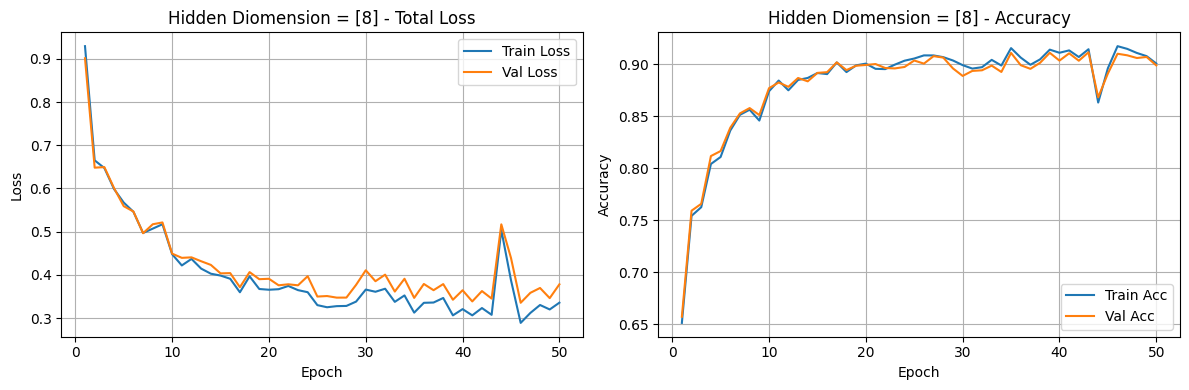

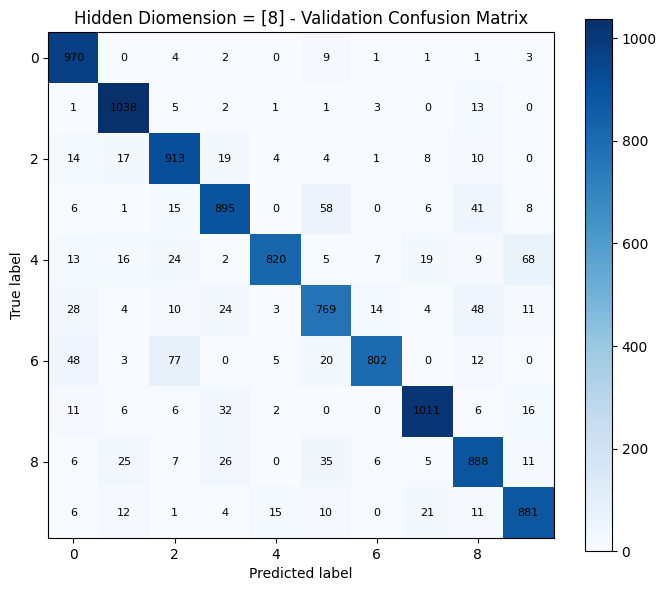

..
Epoch 01/50 | Train Loss: 0.5561 (CE: 0.5561, L2: 0.0000) | Train Acc: 0.8428 | Val Loss: 0.5326 (CE: 0.5326, L2: 0.0000) | Val Acc: 0.8519
Epoch 02/50 | Train Loss: 0.4515 (CE: 0.4515, L2: 0.0000) | Train Acc: 0.8783 | Val Loss: 0.4474 (CE: 0.4474, L2: 0.0000) | Val Acc: 0.8814
Epoch 03/50 | Train Loss: 0.4420 (CE: 0.4420, L2: 0.0000) | Train Acc: 0.8802 | Val Loss: 0.4468 (CE: 0.4468, L2: 0.0000) | Val Acc: 0.8846
Epoch 04/50 | Train Loss: 0.3336 (CE: 0.3336, L2: 0.0000) | Train Acc: 0.9072 | Val Loss: 0.3487 (CE: 0.3487, L2: 0.0000) | Val Acc: 0.9071
Epoch 05/50 | Train Loss: 0.3071 (CE: 0.3071, L2: 0.0000) | Train Acc: 0.9164 | Val Loss: 0.3240 (CE: 0.3240, L2: 0.0000) | Val Acc: 0.9152
Epoch 06/50 | Train Loss: 0.2940 (CE: 0.2940, L2: 0.0000) | Train Acc: 0.9193 | Val Loss: 0.3182 (CE: 0.3182, L2: 0.0000) | Val Acc: 0.9170
Epoch 07/50 | Train Loss: 0.2815 (CE: 0.2815, L2: 0.0000) | Train Acc: 0.9211 | Val Loss: 0.3074 (CE: 0.3074, L2: 0.0000) | Val Acc: 0.9182
Epoch 08/50 | Tra

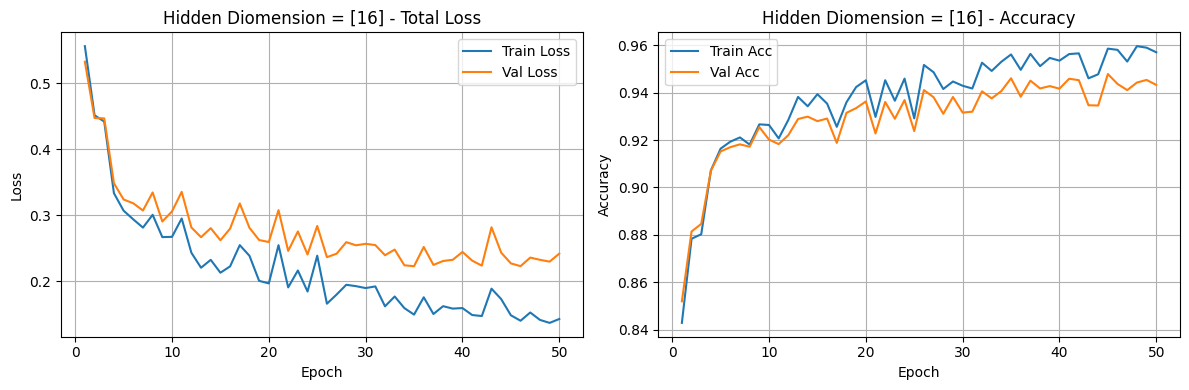

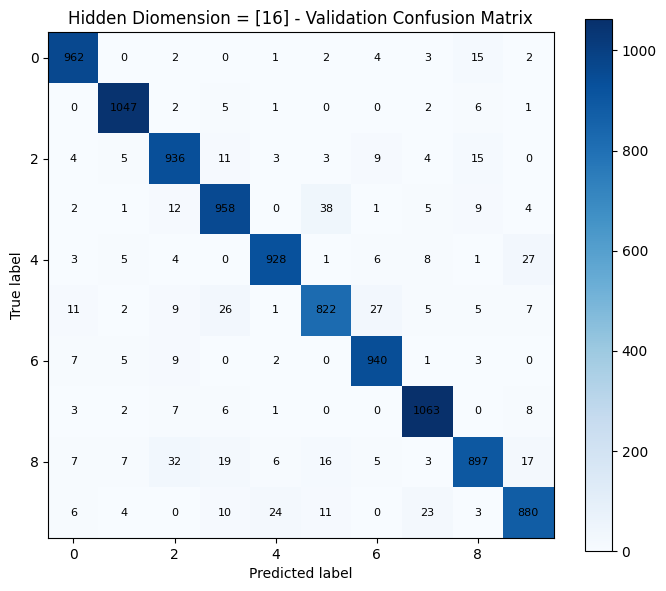

..
Epoch 01/50 | Train Loss: 0.4602 (CE: 0.4602, L2: 0.0000) | Train Acc: 0.8735 | Val Loss: 0.4472 (CE: 0.4472, L2: 0.0000) | Val Acc: 0.8802
Epoch 02/50 | Train Loss: 0.3353 (CE: 0.3353, L2: 0.0000) | Train Acc: 0.9032 | Val Loss: 0.3462 (CE: 0.3462, L2: 0.0000) | Val Acc: 0.9045
Epoch 03/50 | Train Loss: 0.2887 (CE: 0.2887, L2: 0.0000) | Train Acc: 0.9193 | Val Loss: 0.3163 (CE: 0.3163, L2: 0.0000) | Val Acc: 0.9186
Epoch 04/50 | Train Loss: 0.2398 (CE: 0.2398, L2: 0.0000) | Train Acc: 0.9323 | Val Loss: 0.2859 (CE: 0.2859, L2: 0.0000) | Val Acc: 0.9282
Epoch 05/50 | Train Loss: 0.2265 (CE: 0.2265, L2: 0.0000) | Train Acc: 0.9357 | Val Loss: 0.2760 (CE: 0.2760, L2: 0.0000) | Val Acc: 0.9286
Epoch 06/50 | Train Loss: 0.2114 (CE: 0.2114, L2: 0.0000) | Train Acc: 0.9390 | Val Loss: 0.2760 (CE: 0.2760, L2: 0.0000) | Val Acc: 0.9311
Epoch 07/50 | Train Loss: 0.1915 (CE: 0.1915, L2: 0.0000) | Train Acc: 0.9436 | Val Loss: 0.2660 (CE: 0.2660, L2: 0.0000) | Val Acc: 0.9340
Epoch 08/50 | Tra

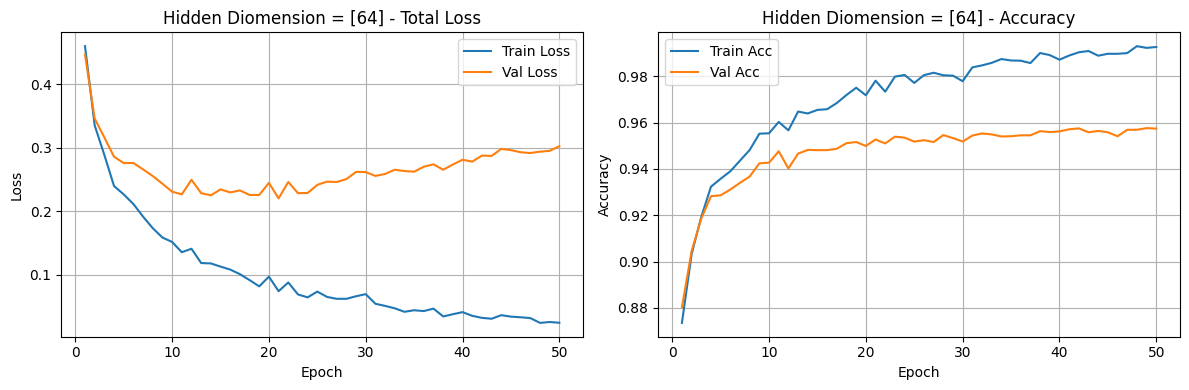

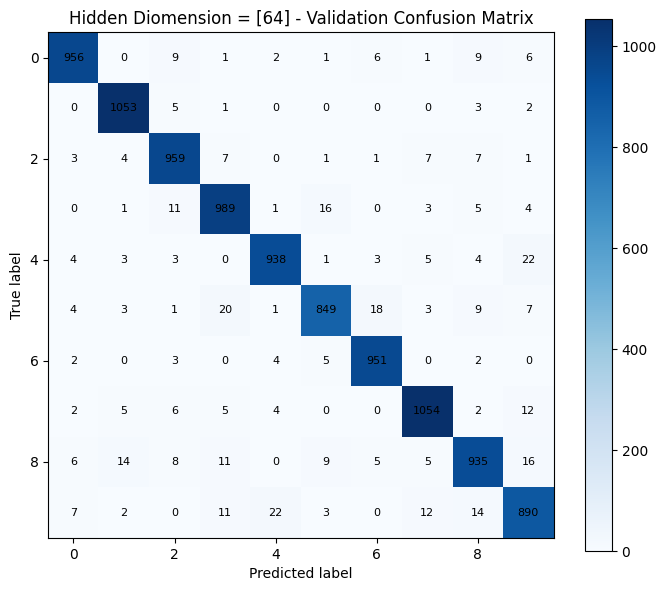

..
Epoch 01/50 | Train Loss: 1.2740 (CE: 1.2740, L2: 0.0000) | Train Acc: 0.4967 | Val Loss: 1.2565 (CE: 1.2565, L2: 0.0000) | Val Acc: 0.5025
Epoch 02/50 | Train Loss: 1.0599 (CE: 1.0599, L2: 0.0000) | Train Acc: 0.5461 | Val Loss: 1.0444 (CE: 1.0444, L2: 0.0000) | Val Acc: 0.5385
Epoch 03/50 | Train Loss: 0.9000 (CE: 0.9000, L2: 0.0000) | Train Acc: 0.6768 | Val Loss: 0.8666 (CE: 0.8666, L2: 0.0000) | Val Acc: 0.6828
Epoch 04/50 | Train Loss: 0.6597 (CE: 0.6597, L2: 0.0000) | Train Acc: 0.7828 | Val Loss: 0.6407 (CE: 0.6407, L2: 0.0000) | Val Acc: 0.7918
Epoch 05/50 | Train Loss: 0.6207 (CE: 0.6207, L2: 0.0000) | Train Acc: 0.8000 | Val Loss: 0.6085 (CE: 0.6085, L2: 0.0000) | Val Acc: 0.8012
Epoch 06/50 | Train Loss: 0.5720 (CE: 0.5720, L2: 0.0000) | Train Acc: 0.8413 | Val Loss: 0.5683 (CE: 0.5683, L2: 0.0000) | Val Acc: 0.8499
Epoch 07/50 | Train Loss: 0.5199 (CE: 0.5199, L2: 0.0000) | Train Acc: 0.8523 | Val Loss: 0.5251 (CE: 0.5251, L2: 0.0000) | Val Acc: 0.8575
Epoch 08/50 | Tra

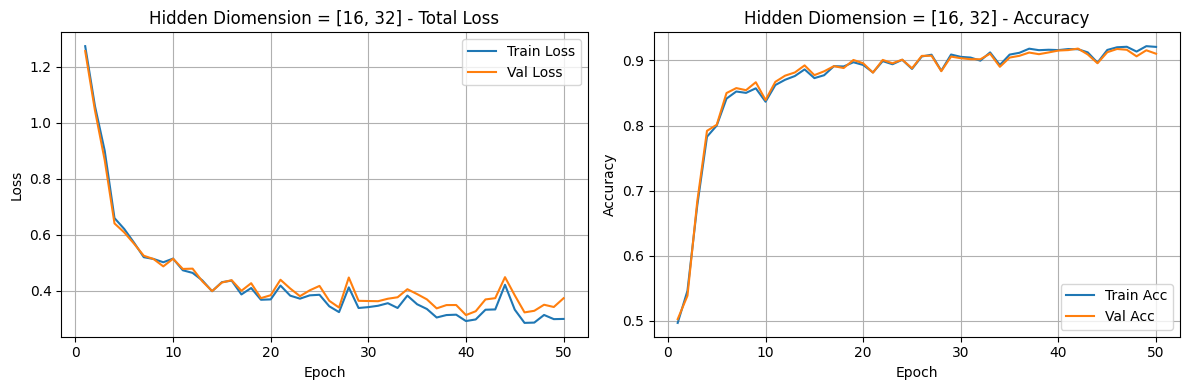

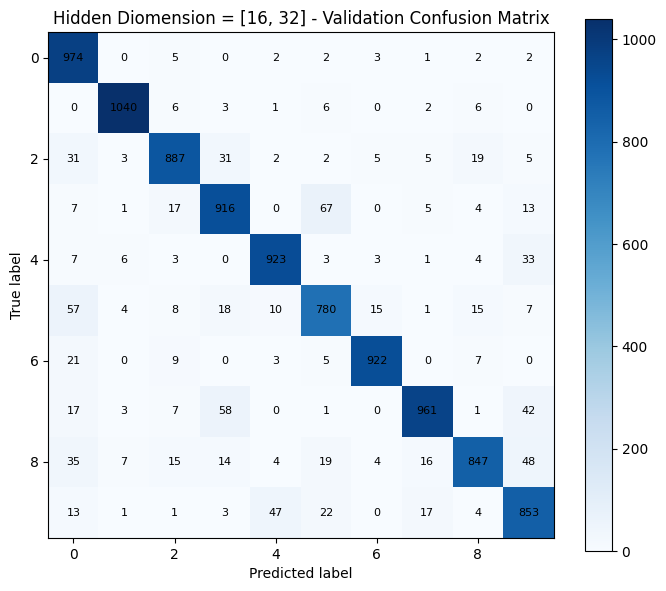

..


In [49]:
hd_results = {}

for hd in config["search_space"]["hidden_dims"]:
    exp_config = copy.deepcopy(selected_config)
    exp_config["model"]["hidden_dims"] = hd

    result = run_experiment(
        exp_config,
        x_train, y_train,
        x_val, y_val,
        x_test, y_test,
        exp_name=f"Hidden Diomension = {hd}",
        early_stopping=False
    )

    hd_results[f"hd={hd}"] = result

    print(input("I am waiting"))

In [58]:
print("num of neuron in hidden dimension comparison:")
print("-" * 70)
print(f"{'Experiment':<20} {'Train Loss':<12} {'Train Acc':<12} {'Val Loss':<12} {'Val Acc':<12}")
print("-" * 70)

for name, result in hd_results.items():
    print(
        f"{name:<20} "
        f"{result['train_loss']:<12.4f}"
        f"{result['train_acc']:<12.4f}"
        f"{result['val_loss']:<12.4f} "
        f"{result['val_acc']:<12.4f}"
    )

num of neuron in hidden dimension comparison:
----------------------------------------------------------------------
Experiment           Train Loss   Train Acc    Val Loss     Val Acc     
----------------------------------------------------------------------
hd=[8]               0.3359      0.9005      0.3784       0.8987      
hd=[16]              0.1431      0.9571      0.2420       0.9433      
hd=[64]              0.0242      0.9926      0.3024       0.9574      
hd=[16, 32]          0.2993      0.9208      0.3733       0.9103      
hd=[32]              0.2993      0.9208      0.3733       0.9103      


In [202]:
selected_config["model"]["hidden_dims"] = [64]

## Q2.14 - L2 regularization

Epoch 01/50 | Train Loss: 0.4602 (CE: 0.4602, L2: 0.0000) | Train Acc: 0.8735 | Val Loss: 0.4472 (CE: 0.4472, L2: 0.0000) | Val Acc: 0.8802
Epoch 02/50 | Train Loss: 0.3353 (CE: 0.3353, L2: 0.0000) | Train Acc: 0.9032 | Val Loss: 0.3462 (CE: 0.3462, L2: 0.0000) | Val Acc: 0.9045
Epoch 03/50 | Train Loss: 0.2887 (CE: 0.2887, L2: 0.0000) | Train Acc: 0.9193 | Val Loss: 0.3163 (CE: 0.3163, L2: 0.0000) | Val Acc: 0.9186
Epoch 04/50 | Train Loss: 0.2398 (CE: 0.2398, L2: 0.0000) | Train Acc: 0.9323 | Val Loss: 0.2859 (CE: 0.2859, L2: 0.0000) | Val Acc: 0.9282
Epoch 05/50 | Train Loss: 0.2265 (CE: 0.2265, L2: 0.0000) | Train Acc: 0.9357 | Val Loss: 0.2760 (CE: 0.2760, L2: 0.0000) | Val Acc: 0.9286
Epoch 06/50 | Train Loss: 0.2114 (CE: 0.2114, L2: 0.0000) | Train Acc: 0.9390 | Val Loss: 0.2760 (CE: 0.2760, L2: 0.0000) | Val Acc: 0.9311
Epoch 07/50 | Train Loss: 0.1915 (CE: 0.1915, L2: 0.0000) | Train Acc: 0.9436 | Val Loss: 0.2660 (CE: 0.2660, L2: 0.0000) | Val Acc: 0.9340
Epoch 08/50 | Train 

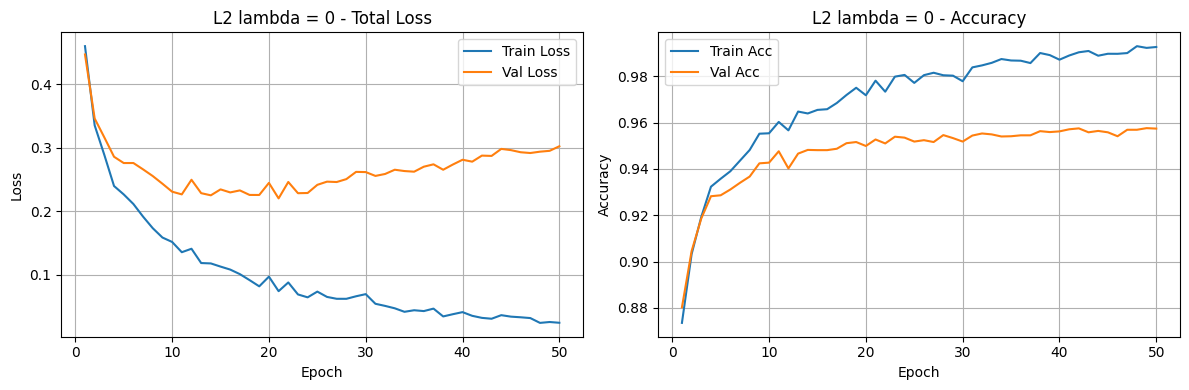

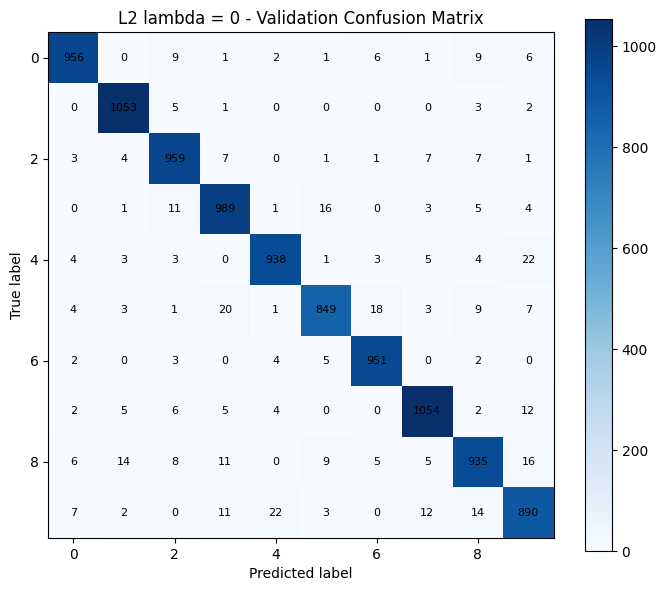

..
Epoch 01/50 | Train Loss: 0.4515 (CE: 0.4515, L2: 0.0000) | Train Acc: 0.8739 | Val Loss: 0.4381 (CE: 0.4378, L2: 0.0002) | Val Acc: 0.8806
Epoch 02/50 | Train Loss: 0.3360 (CE: 0.3359, L2: 0.0000) | Train Acc: 0.9031 | Val Loss: 0.3452 (CE: 0.3450, L2: 0.0002) | Val Acc: 0.9066
Epoch 03/50 | Train Loss: 0.2761 (CE: 0.2761, L2: 0.0000) | Train Acc: 0.9220 | Val Loss: 0.3041 (CE: 0.3039, L2: 0.0002) | Val Acc: 0.9201
Epoch 04/50 | Train Loss: 0.2319 (CE: 0.2318, L2: 0.0000) | Train Acc: 0.9338 | Val Loss: 0.2757 (CE: 0.2754, L2: 0.0002) | Val Acc: 0.9295
Epoch 05/50 | Train Loss: 0.2171 (CE: 0.2170, L2: 0.0000) | Train Acc: 0.9373 | Val Loss: 0.2625 (CE: 0.2623, L2: 0.0002) | Val Acc: 0.9321
Epoch 06/50 | Train Loss: 0.1976 (CE: 0.1975, L2: 0.0000) | Train Acc: 0.9422 | Val Loss: 0.2536 (CE: 0.2533, L2: 0.0002) | Val Acc: 0.9360
Epoch 07/50 | Train Loss: 0.1857 (CE: 0.1856, L2: 0.0000) | Train Acc: 0.9443 | Val Loss: 0.2593 (CE: 0.2591, L2: 0.0002) | Val Acc: 0.9349
Epoch 08/50 | Tra

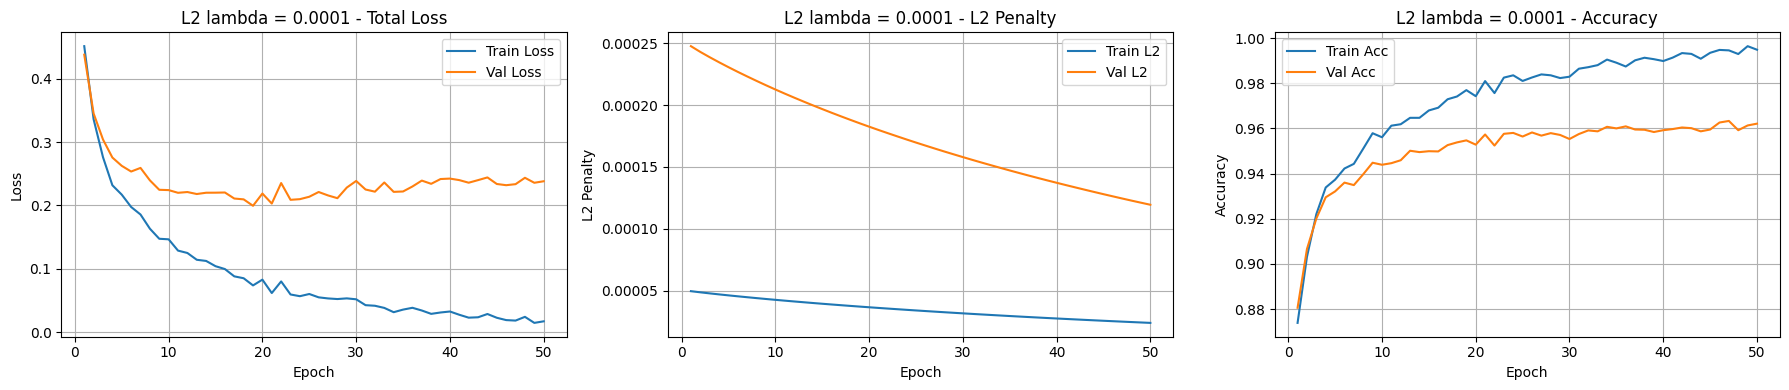

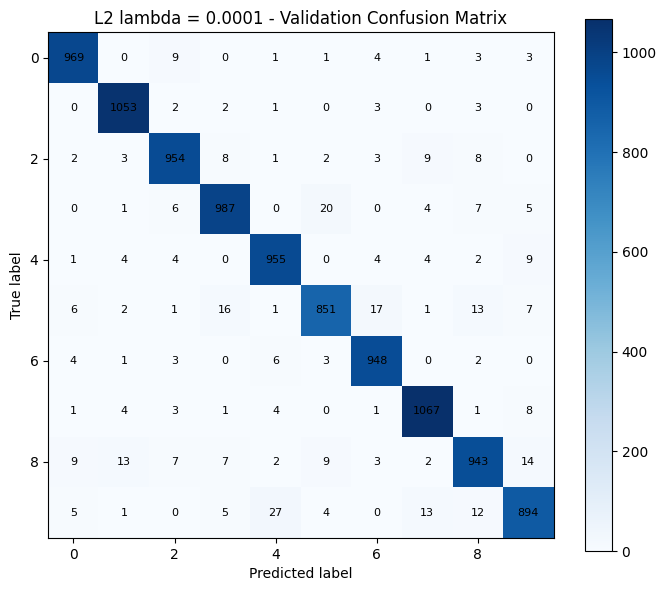

..
Epoch 01/50 | Train Loss: 0.4392 (CE: 0.4388, L2: 0.0004) | Train Acc: 0.8761 | Val Loss: 0.4256 (CE: 0.4234, L2: 0.0022) | Val Acc: 0.8852
Epoch 02/50 | Train Loss: 0.2997 (CE: 0.2994, L2: 0.0004) | Train Acc: 0.9110 | Val Loss: 0.3110 (CE: 0.3092, L2: 0.0018) | Val Acc: 0.9134
Epoch 03/50 | Train Loss: 0.2441 (CE: 0.2438, L2: 0.0003) | Train Acc: 0.9294 | Val Loss: 0.2724 (CE: 0.2708, L2: 0.0016) | Val Acc: 0.9268
Epoch 04/50 | Train Loss: 0.1910 (CE: 0.1907, L2: 0.0003) | Train Acc: 0.9428 | Val Loss: 0.2268 (CE: 0.2254, L2: 0.0013) | Val Acc: 0.9384
Epoch 05/50 | Train Loss: 0.1776 (CE: 0.1773, L2: 0.0002) | Train Acc: 0.9475 | Val Loss: 0.2206 (CE: 0.2194, L2: 0.0011) | Val Acc: 0.9393
Epoch 06/50 | Train Loss: 0.1450 (CE: 0.1448, L2: 0.0002) | Train Acc: 0.9558 | Val Loss: 0.1956 (CE: 0.1946, L2: 0.0010) | Val Acc: 0.9440
Epoch 07/50 | Train Loss: 0.1432 (CE: 0.1430, L2: 0.0002) | Train Acc: 0.9548 | Val Loss: 0.2002 (CE: 0.1994, L2: 0.0008) | Val Acc: 0.9467
Epoch 08/50 | Tra

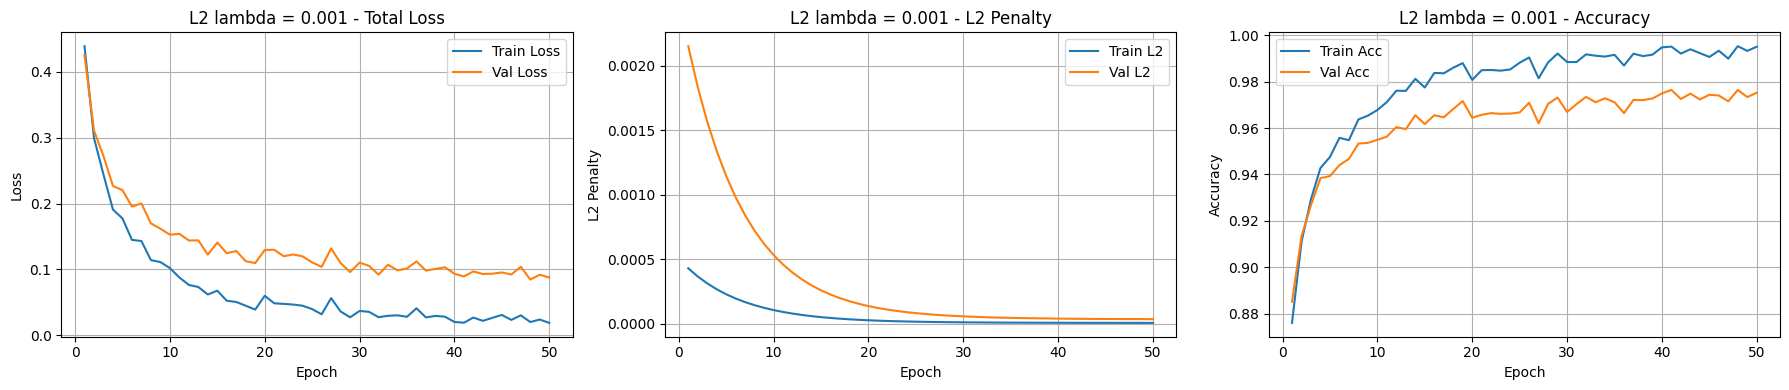

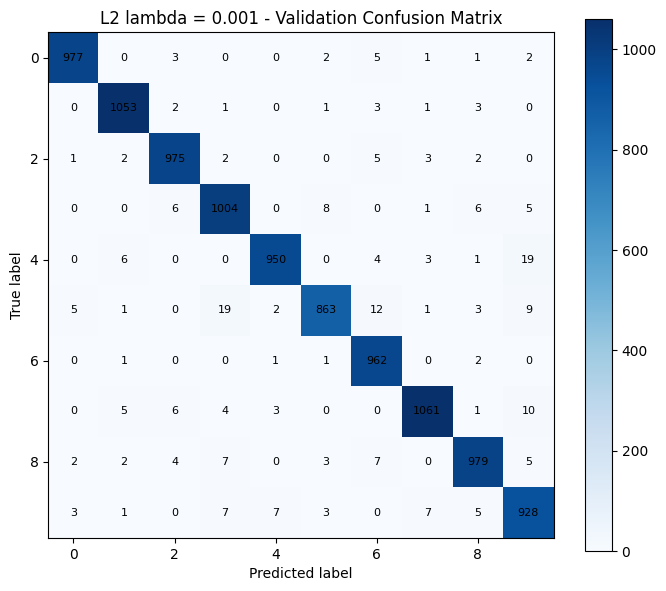

..


In [206]:
l2_results = {}

for l2_lambda in config["search_space"]["l2_lambda"]:
    exp_config = copy.deepcopy(selected_config)
    exp_config["train"]["l2_lambda"] = l2_lambda

    result = run_experiment(
        exp_config,
        x_train, y_train,
        x_val, y_val,
        x_test, y_test,
        exp_name=f"L2 lambda = {l2_lambda:g}",
        early_stopping=False
    )

    l2_results[l2_lambda] = result

    print(input("I am waiting:"))


In [217]:
print("L2-regularization comparison:")
print("-" * 110)
print(
    f"{'Lambda':<7} {'Train Loss':<12} {'Train CE':<12} {'Train L2':<12} "
    f"{'Val Loss':<12} {'Val CE':<12} {'Val L2':<12} {'Val Acc':<12}"
)
print("-" * 110)

for l2_lambda, result in l2_results.items():
    print(
        f"{l2_lambda:<7g} "
        f"{result['train_loss']:<12.4f} "
        f"{result['train_ce_loss']:<12.4f} "
        f"{result['train_reg_loss']:<12.4f} "
        f"{result['val_loss']:<12.4f} "
        f"{result['val_ce_loss']:<12.4f} "
        f"{result['val_reg_loss']:<12.4f} "
        f"{result['val_acc']:<12.4f}"
        f"{result['test_acc']:<12.4f}"
    )


L2-regularization comparison:
--------------------------------------------------------------------------------------------------------------
Lambda  Train Loss   Train CE     Train L2     Val Loss     Val CE       Val L2       Val Acc     
--------------------------------------------------------------------------------------------------------------
0       0.0242       0.0242       0.0000       0.3024       0.3024       0.0000       0.9574      0.9537      
0.0001  0.0170       0.0170       0.0000       0.2382       0.2381       0.0001       0.9621      0.9595      
0.001   0.0189       0.0188       0.0000       0.0877       0.0877       0.0000       0.9752      0.9749      


In [208]:
selected_config["train"]["l2_lambda"] = 0.001

## Early Stopping

In [ ]:
exp_config = copy.deepcopy(selected_config)
exp_config["train"]["l2_lambda"] = 0.0


Epoch 01/50 | Train Loss: 0.4602 (CE: 0.4602, L2: 0.0000) | Train Acc: 0.8735 | Val Loss: 0.4472 (CE: 0.4472, L2: 0.0000) | Val Acc: 0.8802
Epoch 02/50 | Train Loss: 0.3353 (CE: 0.3353, L2: 0.0000) | Train Acc: 0.9032 | Val Loss: 0.3462 (CE: 0.3462, L2: 0.0000) | Val Acc: 0.9045
Epoch 03/50 | Train Loss: 0.2887 (CE: 0.2887, L2: 0.0000) | Train Acc: 0.9193 | Val Loss: 0.3163 (CE: 0.3163, L2: 0.0000) | Val Acc: 0.9186
Epoch 04/50 | Train Loss: 0.2398 (CE: 0.2398, L2: 0.0000) | Train Acc: 0.9323 | Val Loss: 0.2859 (CE: 0.2859, L2: 0.0000) | Val Acc: 0.9282
Epoch 05/50 | Train Loss: 0.2265 (CE: 0.2265, L2: 0.0000) | Train Acc: 0.9357 | Val Loss: 0.2760 (CE: 0.2760, L2: 0.0000) | Val Acc: 0.9286
Epoch 06/50 | Train Loss: 0.2114 (CE: 0.2114, L2: 0.0000) | Train Acc: 0.9390 | Val Loss: 0.2760 (CE: 0.2760, L2: 0.0000) | Val Acc: 0.9311
Epoch 07/50 | Train Loss: 0.1915 (CE: 0.1915, L2: 0.0000) | Train Acc: 0.9436 | Val Loss: 0.2660 (CE: 0.2660, L2: 0.0000) | Val Acc: 0.9340
Epoch 08/50 | Train 

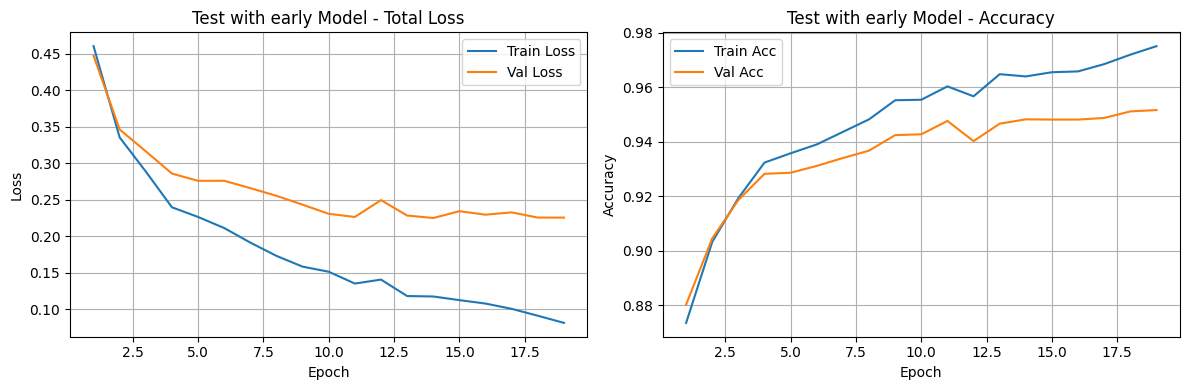

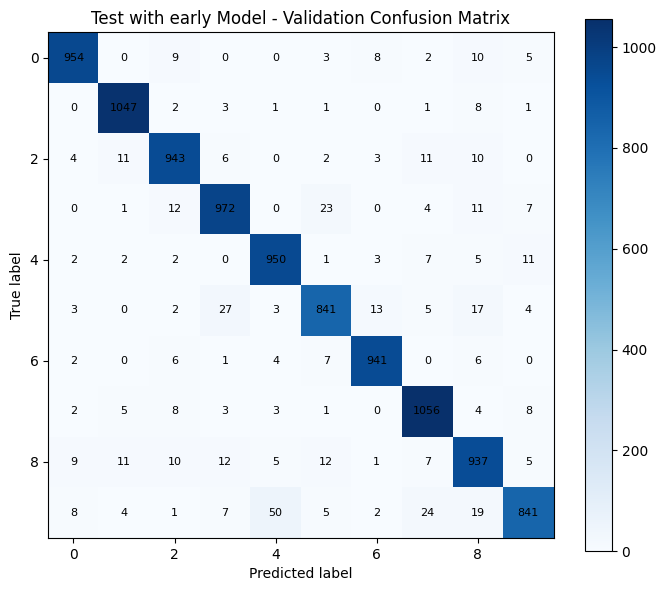

In [ ]:
Early_stopped_results = run_experiment(
    exp_config,
    x_train, y_train,
    x_val, y_val,
    x_test, y_test,
    exp_name="Test with early Model",
    early_stopping=True,
    patience=5,
    min_delta=1e-4
)

In [244]:
with open("./config/selected_config.yaml", "w") as f:
    yaml.dump(selected_config, f, sort_keys=False)

## Test Data

In [245]:
with open("./config/selected_config.yaml", "r") as f:
    config = yaml.safe_load(f)

selected_config = copy.deepcopy(config)

In [230]:
best_config = copy.deepcopy(selected_config)
best_model = build_model_from_config(best_config)

best_history = train_model(
    best_model,
    x_train, y_train,
    x_val, y_val,
    epochs=best_config["train"]["epochs"],
    batch_size=best_config["train"]["batch_size"],
    seed=best_config["seed"],
    early_stopping=False
)

Epoch 01/50 | Train Loss: 0.4392 (CE: 0.4388, L2: 0.0004) | Train Acc: 0.8761 | Val Loss: 0.4256 (CE: 0.4234, L2: 0.0022) | Val Acc: 0.8852
Epoch 02/50 | Train Loss: 0.2997 (CE: 0.2994, L2: 0.0004) | Train Acc: 0.9110 | Val Loss: 0.3110 (CE: 0.3092, L2: 0.0018) | Val Acc: 0.9134
Epoch 03/50 | Train Loss: 0.2441 (CE: 0.2438, L2: 0.0003) | Train Acc: 0.9294 | Val Loss: 0.2724 (CE: 0.2708, L2: 0.0016) | Val Acc: 0.9268
Epoch 04/50 | Train Loss: 0.1910 (CE: 0.1907, L2: 0.0003) | Train Acc: 0.9428 | Val Loss: 0.2268 (CE: 0.2254, L2: 0.0013) | Val Acc: 0.9384
Epoch 05/50 | Train Loss: 0.1776 (CE: 0.1773, L2: 0.0002) | Train Acc: 0.9475 | Val Loss: 0.2206 (CE: 0.2194, L2: 0.0011) | Val Acc: 0.9393
Epoch 06/50 | Train Loss: 0.1450 (CE: 0.1448, L2: 0.0002) | Train Acc: 0.9558 | Val Loss: 0.1956 (CE: 0.1946, L2: 0.0010) | Val Acc: 0.9440
Epoch 07/50 | Train Loss: 0.1432 (CE: 0.1430, L2: 0.0002) | Train Acc: 0.9548 | Val Loss: 0.2002 (CE: 0.1994, L2: 0.0008) | Val Acc: 0.9467
Epoch 08/50 | Train 

In [231]:
test_loss, test_ce_loss, test_reg_loss, test_acc, test_preds = evaluate_model(
    best_model, x_test, y_test, return_loss_parts=True
)

test_cm = confusion_matrix_np(y_test, test_preds, num_classes=best_config["model"]["output_dim"])

## Q2.15

Q2.15) Test accuracy of the best model: 0.9749


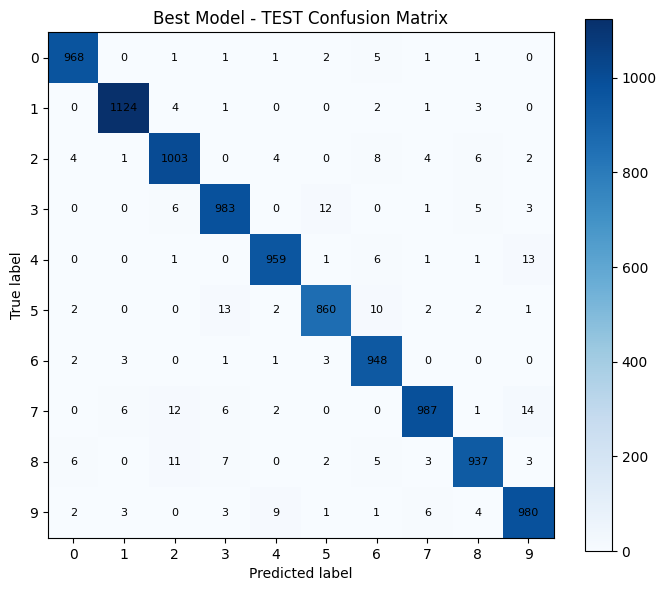

In [240]:
print(f"Q2.15) Test accuracy of the best model: {test_acc:.4f}")

plot_confusion_matrix(test_cm, title="Best Model - TEST Confusion Matrix")

## Q2.16

Per-class accuracy
----------------------------------------
Class 0: 0.9878
Class 1: 0.9903
Class 2: 0.9719
Class 3: 0.9733
Class 4: 0.9766
Class 5: 0.9641
Class 6: 0.9896
Class 7: 0.9601
Class 8: 0.9620
Class 9: 0.9713


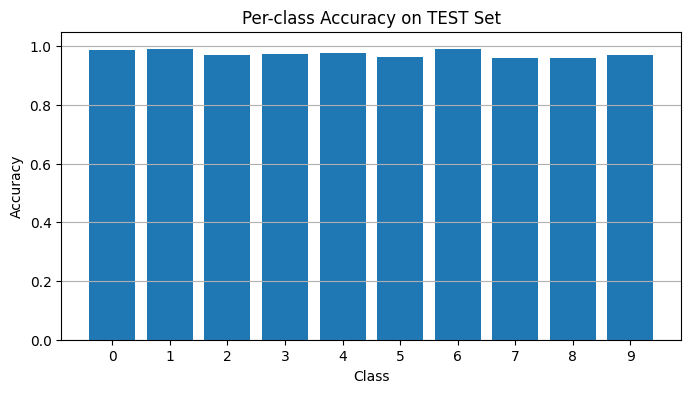

In [234]:
per_class_acc = test_cm.diagonal() / np.maximum(test_cm.sum(axis=1), 1)

print("Per-class accuracy")
print("-" * 40)
for cls, acc in enumerate(per_class_acc):
    print(f"Class {cls}: {acc:.4f}")

plt.figure(figsize=(8, 4))
plt.bar(np.arange(len(per_class_acc)), per_class_acc)
plt.xticks(np.arange(len(per_class_acc)))
plt.xlabel("Class")
plt.ylabel("Accuracy")
plt.title("Per-class Accuracy on TEST Set")
plt.ylim(0, 1.05)
plt.grid(axis="y")
plt.show()

## Q2.19

Number of misclassified test samples: 251


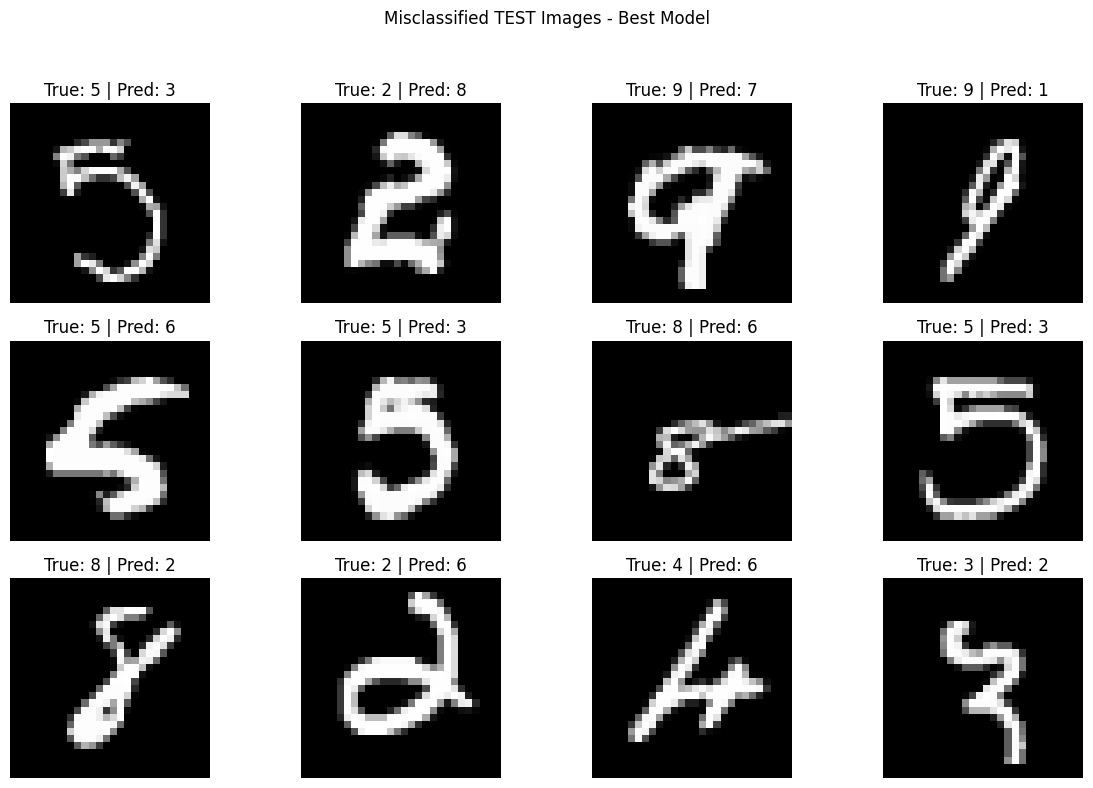

In [241]:
mis_idx = np.where(test_preds != y_test)[0]
print(f"Number of misclassified test samples: {len(mis_idx)}")

num_show = min(12, len(mis_idx))
chosen_mis = np.random.choice(mis_idx, num_show, replace=False)

plt.figure(figsize=(12, 8))
for k, idx in enumerate(chosen_mis, 1):
    plt.subplot(3, 4, k)
    plt.imshow(x_test[idx].reshape(28, 28), cmap="gray")
    plt.title(f"True: {y_test[idx]} | Pred: {test_preds[idx]}")
    plt.axis("off")

plt.suptitle("Misclassified TEST Images - Best Model")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()